In [1]:
# =========================================================
# CELL 1: KHAI BÁO THƯ VIỆN VÀ CẤU HÌNH ĐƯỜNG DẪN
# =========================================================
import pandas as pd
import numpy as np
import lightgbm as lgb
import os
import sys
import pickle
import xgboost as xgb
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import gc
import time
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# 1. CẤU HÌNH ĐƯỜNG DẪN (Bạn hãy kiểm tra kỹ tên file tại đây)
CONFIG = {
    'TEST_FILE': '/kaggle/input/datasets/nguyenleanhtuan07/testdata/random_test_samples_consistent_V4.csv',
    'MODEL_PATH': '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng 1/Tng 1_data.txt',
    'CHILD_LABEL_MAP': '/kaggle/input/datasets/nguyenleanhtuan07/34-labels/label_map_key.csv',
    'OUTPUT_DIR': '/kaggle/working/'
}



# 3. ĐỊNH NGHĨA THỨ TỰ ĐẶC TRƯNG (25 đặc trưng chuẩn)
TRAINED_FEATURES_ORDER = [
    'IAT', 'syn_flag_number', 'psh_flag_number', 'fin_flag_number', 
    'rst_flag_number', 'ack_flag_number', 'Tot sum', 'Protocol Type', 
    'flow_duration', 'Rate', 'Std', 'Variance', 'UDP', 'TCP', 'HTTP', 
    'HTTPS', 'DNS', 'Duration', 'Number', 'ICMP', 'Magnitue', 
    'Header_Length', 'AVG', 'Min', 'Max'
]

#dataV7
FAMILY_MAPPING_LOGIC = {
    'BenignTraffic': 'Slow_Attack_Or_Benign',
    
    'DDoS-ACK_Fragmentation': 'DDoS', 
    'DDoS-UDP_Flood': 'DDoS',
    'DDoS-SlowLoris': 'DDoS',
    'DDoS-ICMP_Flood': 'DDoS',
    'DDoS-RSTFINFlood': 'DDoS',
    'DDoS-PSHACK_Flood': 'DDoS',
    'DDoS-HTTP_Flood': 'DDoS',
    'DDoS-UDP_Fragmentation': 'DDoS',
    'DDoS-TCP_Flood': 'DDoS',
    'DDoS-SYN_Flood': 'DDoS',
    'DDoS-SynonymousIP_Flood': 'DDoS',
    'DDoS-ICMP_Fragmentation': 'DDoS',
    
    'DoS-TCP_Flood': 'DoS', 'DoS-HTTP_Flood': 'DoS', 'DoS-SYN_Flood': 'DoS', 'DoS-UDP_Flood': 'DoS',

    'Mirai-greip_flood': 'Mirai', 'Mirai-greeth_flood': 'Mirai', 'Mirai-udpplain': 'Mirai',

    'Recon-PingSweep': 'Slow_Attack_Or_Benign', 'Recon-OSScan': 'Slow_Attack_Or_Benign', 'VulnerabilityScan': 'Slow_Attack_Or_Benign',
    'Recon-PortScan': 'Slow_Attack_Or_Benign', 'Recon-HostDiscovery': 'Slow_Attack_Or_Benign',
    'SqlInjection': 'Slow_Attack_Or_Benign', 'CommandInjection': 'Slow_Attack_Or_Benign', 'Backdoor_Malware': 'Slow_Attack_Or_Benign',
    'Uploading_Attack': 'Slow_Attack_Or_Benign', 'XSS': 'Slow_Attack_Or_Benign', 'BrowserHijacking': 'Slow_Attack_Or_Benign',
    'DictionaryBruteForce': 'Slow_Attack_Or_Benign', 'MITM-ArpSpoofing': 'Slow_Attack_Or_Benign', 'DNS_Spoofing': 'Slow_Attack_Or_Benign',
}

In [2]:
# =========================================================
# CELL 2: XỬ LÝ DỮ LIỆU ĐẦU VÀO (FEATURES EXTRACTION)
# =========================================================

# 1. ĐỊNH NGHĨA LẠI THỨ TỰ CỘT CHUẨN (Khớp 100% với bộ dữ liệu bạn dùng để train)
# Danh sách này được sắp xếp đúng: flow_duration đứng đầu, Variance đứng cuối
FINAL_TRAINED_FEATURES = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate',
    'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number',
    'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 'ICMP', 'Tot sum', 'Min', 'Max', 'AVG', 'Std',
    'IAT', 'Number', 'Magnitue', 'Variance'
]

# 2. Đọc file test
try:
    df_test = pd.read_csv(CONFIG['TEST_FILE'])
    # Xóa khoảng trắng thừa ở tên cột để tránh lỗi không tìm thấy cột
    df_test.columns = df_test.columns.str.strip()
    print(f"✅ Đã đọc file: {CONFIG['TEST_FILE']}")
    print(f"   -> Số lượng mẫu: {df_test.shape[0]}")
    print(f"   -> Số lượng cột gốc trong file: {df_test.shape[1]}")
except Exception as e:
    print(f"❌ Lỗi khi đọc file test: {e}")

# 3. Trích xuất và Sắp xếp lại cột (Re-order)

try:
    # Việc dùng df_test[FINAL_TRAINED_FEATURES] sẽ tự động:
    # - Chỉ lấy 25 cột cần thiết
    # - Đưa các cột về đúng vị trí mà mô hình LightGBM mong đợi
    X_test = df_test[FINAL_TRAINED_FEATURES].copy()
    
    print("✅ Đã chuẩn hóa thứ tự đặc trưng thành công.")
    print(f"   -> Kích thước đầu vào: {X_test.shape}")
except KeyError as e:
    # Nếu file test thiếu cột nào, chương trình sẽ báo chính xác tên cột đó
    missing_cols = [col for col in FINAL_TRAINED_FEATURES if col not in df_test.columns]
    print(f"❌ Lỗi: File test thiếu các cột sau: {missing_cols}")

# 4. Kiểm tra chất lượng dữ liệu (Xử lý NaN)
nan_count = X_test.isnull().sum().sum()
if nan_count > 0:
    print(f"⚠️ Cảnh báo: Phát hiện {nan_count} giá trị NaN.")
    X_test = X_test.fillna(0)
    print("   -> Đã tự động điền 0 vào các ô trống.")
else:
    print("✅ Dữ liệu sạch (không có NaN).")


✅ Đã đọc file: /kaggle/input/datasets/nguyenleanhtuan07/testdata/random_test_samples_consistent_V4.csv
   -> Số lượng mẫu: 2382160
   -> Số lượng cột gốc trong file: 47
✅ Đã chuẩn hóa thứ tự đặc trưng thành công.
   -> Kích thước đầu vào: (2382160, 25)
✅ Dữ liệu sạch (không có NaN).


In [3]:
# =========================================================
# CELL 3: NẠP MODEL VÀ DỰ ĐOÁN NHÃN HỌ (TẦNG 1 - 4 NHÃN)
# =========================================================

print("Phân loại Tầng 1(DDoS, DoS, Mirai, Slow_attack")

# 1. Nạp mô hình
try:
    model = lgb.Booster(model_file=CONFIG['MODEL_PATH'])
    print(f"✅ Đã nạp mô hình thành công.")
    
    expected_features = model.num_feature()
    current_features = X_test.shape[1]
    
    print(f"   -> AI yêu cầu: {expected_features} đặc trưng.")
    if expected_features != current_features:
        print(f"⚠️ CẢNH BÁO: Số lượng cột không khớp ({current_features}/{expected_features})!")
except Exception as e:
    print(f"❌ Lỗi nạp mô hình: {e}")

# 2. Thực hiện dự đoán
try:
    # Dự đoán trả về ma trận xác suất 4 cột
    y_prob = model.predict(X_test)
    
    # Lấy index có xác suất cao nhất (0, 1, 2, hoặc 3)
    y_pred_idx = np.argmax(y_prob, axis=1)
    
    # --- CẬP NHẬT MAPPING 4 NHÃN ---
    # Đảm bảo thứ tự này khớp với thứ tự bạn đã dùng khi Train model 4 nhãn
    label_map_ho = {
        0: 'Slow_Attack_Or_Benign', 
        1: 'DDoS', 
        2: 'DoS', 
        3: 'Mirai'
    }
    column_names = [label_map_ho[i] for i in range(len(label_map_ho))]
    y_pred_name = [label_map_ho[idx] for idx in y_pred_idx]
    print("✅ Dự đoán hoàn tất!")
except Exception as e:
    print(f"❌ Lỗi trong quá trình dự đoán: {e}")
    # In thêm thông báo để debug nếu model thực tế chỉ có 3 đầu ra
    if 'y_prob' in locals():
        print(f"   -> Số cột xác suất thực tế model trả về: {y_prob.shape[1]}")

# 3. HIỂN THỊ TRỰC QUAN (Tự động điều chỉnh theo số nhãn)


try:
    prob_df = pd.DataFrame(y_prob, columns=column_names)
    prob_df['AI_Du_Doan'] = y_pred_name
except ValueError as e:
    print(f"⚠️ Lỗi hiển thị bảng: {e}")
    print("Có thể số lượng nhãn trong label_map_ho không khớp với số đầu ra của Model.")

# 4. Thống kê tổng quan
print("\n📝 Thống kê số lượng từng nhóm AI dự đoán được:")
counts = pd.Series(y_pred_name).value_counts()
print(counts)

print("\n🚀 Cell 3 hoàn tất!")

Phân loại Tầng 1(DDoS, DoS, Mirai, Slow_attack
✅ Đã nạp mô hình thành công.
   -> AI yêu cầu: 25 đặc trưng.
✅ Dự đoán hoàn tất!

📝 Thống kê số lượng từng nhóm AI dự đoán được:
DDoS                     1052281
Slow_Attack_Or_Benign     658080
DoS                       371799
Mirai                     300000
Name: count, dtype: int64

🚀 Cell 3 hoàn tất!


In [4]:
# =========================================================
# CELL 3.1: KHỞI TẠO MASTER TABLE (QUY ĐỔI NHÃN TỪ CSV)
# =========================================================


if 'df_test' not in locals():
    raise NameError("❌ Lỗi: Biến 'df_test' chưa sẵn sàng.")

# 1. ĐỊNH NGHĨA DANH SÁCH CỘT
columns = [
    'STT', 'Nhãn_Con_Thực_Tế', 'Dự_Đoán_T1_Họ', 'Thực_Tế_T1_Họ',
    'Dự_Đoán_DDoS', 'Thực_Tế_DDoS',
    'Dự_Đoán_DoS', 'Thực_Tế_DoS',
    'Dự_Đoán_Mirai', 'Thực_Tế_Mirai',
    'Dự_Đoán_T2_Mali_Beni', 'Thực_Tế_T2_Mali_Beni',
    'Dự_Đoán_Brute', 'Thực_Tế_Brute',
    'Dự_Đoán_Spoof', 'Thực_Tế_Spoof',
    'Dự_Đoán_Con_Spoof','Thực_Tế_Con_Spoof',
    'Dự_Đoán_Web-Recon', 'Thực_Tế_Web-Recon',
    'Dự_Đoán_Web', 'Thực_Tế_Web',
    'Dự_Đoán_Recon', 'Thực_Tế_Recon',
    'Dự_Đoán_Cuối'
]

# 2. KHỞI TẠO MASTER_DF
master_df = pd.DataFrame('None', index=df_test.index, columns=columns)

# 3. ĐỔ DỮ LIỆU ĐỊNH DANH (STT)
if 'STT' in df_test.columns:
    master_df['STT'] = df_test['STT']
else:
    master_df['STT'] = np.arange(1, len(df_test) + 1)

# 4. QUY ĐỔI NHÃN SỐ SANG CHỮ DỰA TRÊN FILE CSV MAPPING
# Đường dẫn file CSV mapping của bạn (Thay đổi đường dẫn đúng thực tế)
PATH_LABEL_MAPPING = '/kaggle/input/datasets/nguyenleanhtuan07/34-labels/label_map_key.csv' 

try:
    # Đọc file mapping (Giả sử tên cột là Original_Label và Encoded_ID như ảnh bạn gửi)
    mapping_df = pd.read_csv(PATH_LABEL_MAPPING)
    
    # Tạo dictionary để map nhanh: {Encoded_ID: Original_Label}
    label_dict = dict(zip(mapping_df['Encoded_ID'], mapping_df['Original_Label']))
    
    # Tìm cột nhãn số trong df_test (thường là 'label' hoặc 'target')
    raw_label_col = 'label' if 'label' in df_test.columns else 'target'
    
    if raw_label_col in df_test.columns:
        # Thực hiện quy đổi
        master_df['Nhãn_Con_Thực_Tế'] = df_test[raw_label_col].map(label_dict).fillna('None')
        print(f"✅ Đã quy đổi nhãn từ số sang chữ thành công dựa trên file mapping.")
    else:
        print("⚠️ Không tìm thấy cột nhãn số trong df_test để quy đổi.")

except Exception as e:
    print(f"❌ Lỗi khi đọc file mapping hoặc quy đổi nhãn: {e}")
    # Dự phòng: Nếu lỗi thì lấy cột chữ có sẵn hoặc giữ nguyên số
    master_df['Nhãn_Con_Thực_Tế'] = df_test.get('Tên nhãn con thực tế', df_test.get('label', 'None'))


✅ Đã quy đổi nhãn từ số sang chữ thành công dựa trên file mapping.


In [5]:
# =========================================================
# CELL 4: XỬ LÝ KẾT QUẢ VÀ CẬP NHẬT MASTER TABLE
# =========================================================

print("⏳ Đang xử lý kết quả dự đoán Tầng 1 và cập nhật Master Table...")

# 1. Kiểm tra sự tồn tại của Master Table
if 'master_df' not in locals():
    print("⚠️ Cảnh báo: master_df chưa được khởi tạo. Đang chạy lại khởi tạo từ Cell 3.1...")
    master_df = pd.DataFrame(index=df_test.index)
    for col in columns: master_df[col] = 'None'
    master_df['STT'] = np.arange(1, len(df_test) + 1)

# 2. CẬP NHẬT DỰ ĐOÁN TẦNG 1
master_df['Dự_Đoán_T1_Họ'] = y_pred_name

# 3. XỬ LÝ NHÃN THỰC TẾ (CHẾ ĐỘ CÓ NHÃN VS KHÔNG NHÃN)
target_col = None
for col in ['label', 'family_label', 'Label', 'Class']:
    if col in df_test.columns:
        target_col = col
        break

if target_col:
    try:
        # Nạp mapping nhãn con để dịch tên
        child_info = pd.read_csv(CONFIG['CHILD_LABEL_MAP'])
        id_to_child_name = dict(zip(child_info['Encoded_ID'].astype(str), child_info['Original_Label'].str.strip()))
        
        # Dịch nhãn con thực tế
        raw_labels = df_test[target_col].astype(str).str.strip()
        master_df['Nhãn_Con_Thực_Tế'] = raw_labels.map(id_to_child_name).fillna(raw_labels)
        
        # Cập nhật Nhãn Họ thực tế
        master_df['Thực_Tế_T1_Họ'] = master_df['Nhãn_Con_Thực_Tế'].map(FAMILY_MAPPING_LOGIC).fillna('None')
        
        print(f"✅ Tìm thấy nhãn thực tế. Đã cập nhật đối chiếu.")
        
        # Tính Accuracy Tầng 1
        valid_rows = master_df[master_df['Thực_Tế_T1_Họ'] != 'None']
        if len(valid_rows) > 0:
            correct = (valid_rows['Dự_Đoán_T1_Họ'] == valid_rows['Thực_Tế_T1_Họ']).sum()
            accuracy = (correct / len(valid_rows)) * 100
            print(f"📊 Độ chính xác Tầng 1 (Họ): {accuracy:.2f}%")

    except Exception as e:
        print(f"⚠️ Có cột nhãn nhưng không thể xử lý mapping: {e}")
        # Nếu lỗi mapping, các cột Thực Tế vẫn giữ 'None'
else:
    # TRƯỜNG HỢP KHÔNG CÓ NHÃN (Lưu ý của bạn)
    print("ℹ️ Bộ test không có nhãn (Unlabeled). Các cột 'Thực_Tế' sẽ được giữ là 'None'.")
    master_df['Nhãn_Con_Thực_Tế'] = 'None'
    master_df['Thực_Tế_T1_Họ'] = 'None'

⏳ Đang xử lý kết quả dự đoán Tầng 1 và cập nhật Master Table...
✅ Tìm thấy nhãn thực tế. Đã cập nhật đối chiếu.
📊 Độ chính xác Tầng 1 (Họ): 100.00%


In [6]:
# =========================================================
# CELL 4.1: PHÂN LOẠI CHI TIẾT TẦNG DDoS (CẬP NHẬT MASTER & XUẤT FILE)
# =========================================================


# 1. CẤU HÌNH ĐƯỜNG DẪN
PATH_DDoS_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con DDoS/DDoS_data.txt'
PATH_DDoS_LABELS = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con DDoS/DDoS_Nhn.pkl'

SELECTED_FEATURES_DDoS = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 
    'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 
    'ack_flag_number', 'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 
    'ICMP', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 
    'IAT', 'Number', 'Magnitue', 'Variance'
]

# 2. KIỂM TRA ĐIỀU KIỆN
try:
    ddos_indices = master_df[master_df['Dự_Đoán_T1_Họ'] == 'DDoS'].index
except (NameError, KeyError):
    ddos_indices = pd.Index([])

if len(ddos_indices) == 0:
    print("ℹ️ Bỏ qua Cell: AI Tầng 1 không tìm thấy mẫu nào thuộc nhóm DDoS.")
else:
    print(f"🚀 Tìm thấy {len(ddos_indices)} mẫu DDoS. Bắt đầu phân loại...")
    
    if not os.path.exists(PATH_DDoS_MODEL):
        print(f"❌ Lỗi: Không tìm thấy file model.")
    else:
        try:
            # 3. NẠP MODEL VÀ DỰ ĐOÁN
            model_ddos = lgb.Booster(model_file=PATH_DDoS_MODEL)
            meta_data = joblib.load(PATH_DDoS_LABELS)
            mapping_labels_ddos = meta_data['label_map'] if isinstance(meta_data, dict) else meta_data
            
            X_ddos = df_test.loc[ddos_indices, SELECTED_FEATURES_DDoS]
            y_prob_ddos = model_ddos.predict(X_ddos)
            y_pred_idx = np.argmax(y_prob_ddos, axis=1) if len(y_prob_ddos.shape) > 1 else np.round(y_prob_ddos).astype(int)

            if isinstance(mapping_labels_ddos, dict):
                y_pred_names = [mapping_labels_ddos.get(int(idx), f"ID_{idx}") for idx in y_pred_idx]
            elif hasattr(mapping_labels_ddos, 'inverse_transform'):
                y_pred_names = mapping_labels_ddos.inverse_transform(y_pred_idx)
            else:
                y_pred_names = [f"ID_{idx}" for idx in y_pred_idx]

            # 4. CẬP NHẬT VÀO MASTER_DF
            master_df.loc[ddos_indices, 'Dự_Đoán_DDoS'] = y_pred_names
            
            ddos_list = [
                'DDoS-RST_Fragmentation', 'DDoS-ACK_Fragmentation', 'DDoS-ICMP_Fragmentation', 
                'DDoS-UDP_Fragmentation', 'DDoS-UDP_Flood', 'DDoS-ICMP_Flood', 
                'DDoS-RSTFINFlood', 'DDoS-SynonymousIP_Flood', 'DDoS-SlowLoris', 
                'DDoS-HTTP_Flood', 'DDoS-SYN_Flood', 'DDoS-PSHACK_Flood', 'DDoS-TCP_Flood'
            ]
            
            def map_ddos_real(val):
                if val == 'None' or pd.isna(val): return 'None'
                return val if val in ddos_list else 'None'

            master_df.loc[ddos_indices, 'Thực_Tế_DDoS'] = master_df.loc[ddos_indices, 'Nhãn_Con_Thực_Tế'].apply(map_ddos_real)
            print("✅ Đã cập nhật kết quả DDoS vào Master Table.")


        except Exception as e:
            print(f"❌ Lỗi thực thi: {e}")

print("\n✅ Hoàn tất tiến trình Tầng DDoS.")

🚀 Tìm thấy 1052281 mẫu DDoS. Bắt đầu phân loại...
✅ Đã cập nhật kết quả DDoS vào Master Table.

✅ Hoàn tất tiến trình Tầng DDoS.


In [7]:
# =========================================================
# CELL 4.2: PHÂN LOẠI CHI TIẾT TẦNG DoS & CẬP NHẬT TIẾP VÀO MASTER
# =========================================================

# 1. CẤU HÌNH ĐƯỜNG DẪN
PATH_DoS_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con Dos/DoS_data.txt'
PATH_DoS_LABELS = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con Dos/DoS_nhn.pkl'

SELECTED_FEATURES_DoS = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 
    'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 
    'ack_flag_number', 'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 
    'ICMP', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 
    'IAT', 'Number', 'Magnitue', 'Variance'
]

# 2. LỌC INDEX (Chỉ lấy những dòng T1 dự đoán là DoS để chạy model chuyên gia)
try:
    dos_indices = master_df[master_df['Dự_Đoán_T1_Họ'] == 'DoS'].index
except (NameError, KeyError):
    dos_indices = pd.Index([])

if len(dos_indices) == 0:
    print("ℹ️ Bỏ qua: Tầng 1 không dự đoán mẫu nào là DoS, không có gì để cập nhật.")
else:
    print(f"🚀 Tìm thấy {len(dos_indices)} mẫu DoS. Đang phân loại chuyên sâu...")
    
    if not os.path.exists(PATH_DoS_MODEL):
        print(f"❌ Lỗi: Không tìm thấy file model DoS.")
    else:
        try:
            # 3. NẠP MODEL VÀ DỰ ĐOÁN
            model_dos = lgb.Booster(model_file=PATH_DoS_MODEL)
            meta_data = joblib.load(PATH_DoS_LABELS)
            mapping_labels_dos = meta_data['label_map'] if isinstance(meta_data, dict) else meta_data
            
            X_dos = df_test.loc[dos_indices, SELECTED_FEATURES_DoS]
            y_prob_dos = model_dos.predict(X_dos)
            y_pred_idx = np.argmax(y_prob_dos, axis=1) if len(y_prob_dos.shape) > 1 else np.round(y_prob_dos).astype(int)

            # Giải mã nhãn
            if isinstance(mapping_labels_dos, dict):
                y_pred_names = [mapping_labels_dos.get(int(idx), f"ID_{idx}") for idx in y_pred_idx]
            elif hasattr(mapping_labels_dos, 'inverse_transform'):
                y_pred_names = mapping_labels_dos.inverse_transform(y_pred_idx)
            else:
                y_pred_names = [f"ID_{idx}" for idx in y_pred_idx]

            # 4. CẬP NHẬT TRỰC TIẾP VÀO MASTER_DF (Khởi tạo từ Cell 3.1)
            master_df.loc[dos_indices, 'Dự_Đoán_DoS'] = y_pred_names
            
            # Cập nhật nhãn thực tế cho DoS (để đối soát)
            dos_list = ['DoS-UDP_Flood', 'DoS-TCP_Flood', 'DoS-SYN_Flood', 'DoS-HTTP_Flood']
            master_df.loc[dos_indices, 'Thực_Tế_DoS'] = master_df.loc[dos_indices, 'Nhãn_Con_Thực_Tế'].apply(
                lambda x: x if x in dos_list else 'None'
            )
            
            print("✅ Cập nhật nhánh DoS vào Master Table thành công.")



        except Exception as e:
            print(f"❌ Lỗi trong quá trình xử lý DoS: {e}")

print("\n✅ Hoàn tất Cell Tầng DoS.")

🚀 Tìm thấy 371799 mẫu DoS. Đang phân loại chuyên sâu...
✅ Cập nhật nhánh DoS vào Master Table thành công.

✅ Hoàn tất Cell Tầng DoS.


In [8]:
# =========================================================
# CELL 4.3: PHÂN LOẠI CHI TIẾT TẦNG Mirai & CẬP NHẬT MASTER
# =========================================================

# 1. CẤU HÌNH ĐƯỜNG DẪN
PATH_Mirai_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con Mirai/Mirai_data.txt'
PATH_Mirai_LABELS = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con Mirai/Mirai_nhn.pkl'

SELECTED_FEATURES_Mirai = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 
    'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 
    'ack_flag_number', 'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 
    'ICMP', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 
    'IAT', 'Number', 'Magnitue', 'Variance'
]

# 2. KIỂM TRA ĐIỀU KIỆN: Lấy index các mẫu T1 đoán là Mirai
try:
    mirai_indices = master_df[master_df['Dự_Đoán_T1_Họ'] == 'Mirai'].index
except (NameError, KeyError):
    mirai_indices = pd.Index([])

if len(mirai_indices) == 0:
    print("ℹ️ Bỏ qua: Tầng 1 không tìm thấy mẫu nào thuộc nhóm Mirai.")
else:
    print(f"🚀 Tìm thấy {len(mirai_indices)} mẫu Mirai. Đang phân loại chuyên sâu...")
    
    if not os.path.exists(PATH_Mirai_MODEL):
        print(f"❌ Lỗi: Không tìm thấy file model Mirai tại {PATH_Mirai_MODEL}")
    else:
        try:
            # 3. NẠP MODEL VÀ DỰ ĐOÁN
            model_mirai = lgb.Booster(model_file=PATH_Mirai_MODEL)
            meta_data = joblib.load(PATH_Mirai_LABELS)
            
            # Xử lý mapping linh hoạt
            if isinstance(meta_data, dict) and 'label_map' in meta_data:
                mapping_labels_mirai = meta_data['label_map']
            else:
                mapping_labels_mirai = meta_data

            X_mirai = df_test.loc[mirai_indices, SELECTED_FEATURES_Mirai]
            y_prob_mirai = model_mirai.predict(X_mirai)
            y_pred_idx = np.argmax(y_prob_mirai, axis=1) if len(y_prob_mirai.shape) > 1 else np.round(y_prob_mirai).astype(int)

            # Giải mã nhãn
            if isinstance(mapping_labels_mirai, dict):
                y_pred_names = [mapping_labels_mirai.get(int(idx), f"ID_{idx}") for idx in y_pred_idx]
            elif hasattr(mapping_labels_mirai, 'inverse_transform'):
                y_pred_names = mapping_labels_mirai.inverse_transform(y_pred_idx)
            else:
                y_pred_names = [f"ID_{idx}" for idx in y_pred_idx]

            # 4. CẬP NHẬT VÀO MASTER_DF
            # Điền kết quả Dự đoán
            master_df.loc[mirai_indices, 'Dự_Đoán_Mirai'] = y_pred_names
            
            # Cập nhật nhãn Thực tế (Chỉ giữ nhãn Mirai, còn lại để None)
            # Bạn có thể bổ sung thêm các nhãn Mirai khác vào list này nếu model có nhiều hơn 3 nhãn
            mirai_list = ['Mirai-Greethood', 'Mirai-UDPPlain', 'Mirai-HTTP_Flood', 'Mirai-Greynoise'] 
            
            master_df.loc[mirai_indices, 'Thực_Tế_Mirai'] = master_df.loc[mirai_indices, 'Nhãn_Con_Thực_Tế'].apply(
                lambda x: x if any(m in str(x) for m in ['Mirai']) else 'None'
            )
            
            print("✅ Đã cập nhật nhánh Mirai vào Master Table.")


        except Exception as e:
            print(f"❌ Lỗi thực thi Tầng Mirai: {e}")

print("\n✅ Hoàn tất tiến trình Tầng Mirai.")

🚀 Tìm thấy 300000 mẫu Mirai. Đang phân loại chuyên sâu...
✅ Đã cập nhật nhánh Mirai vào Master Table.

✅ Hoàn tất tiến trình Tầng Mirai.


In [9]:
# =========================================================
# CELL 5: PHÂN LOẠI CHI TIẾT TẦNG 2 (BENIGN VS MALICIOUS) & CẬP NHẬT MASTER
# =========================================================


# 1. CẤU HÌNH ĐƯỜNG DẪN TẦNG 2
PATH_T2_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng benign và mã độc/Tng 2_data.txt'
PATH_T2_CONFIG = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng benign và mã độc/Tng 2_nhn.pkl'

print("🛡️ Đang khởi tạo bộ phân loại Tầng 2...")

# 2. KIỂM TRA ĐIỀU KIỆN: Lọc index từ Tầng 1 (Nhóm nghi vấn Slow Attack hoặc Benign)
try:
    # Lưu ý: Tên nhãn 'Slow_Attack_Or_Benign' phải khớp với kết quả dự đoán của Tầng 1 trong master_df
    target_indices = master_df[master_df['Dự_Đoán_T1_Họ'] == 'Slow_Attack_Or_Benign'].index
except (NameError, KeyError):
    target_indices = pd.Index([])

if not os.path.exists(PATH_T2_MODEL) or not os.path.exists(PATH_T2_CONFIG):
    print("❌ Lỗi: Không tìm thấy file trọng số hoặc cấu hình Tầng 2!")
elif len(target_indices) == 0:
    print("ℹ️ Không có mẫu nào thuộc nhóm 'Slow_Attack_Or_Benign'. Bỏ qua cập nhật Tầng 2.")
else:
    try:
        # 3. LOAD MODEL VÀ CẤU HÌNH
        with open(PATH_T2_CONFIG, 'rb') as f:
            config_t2 = pickle.load(f)
        
        model_t2 = lgb.Booster(model_file=PATH_T2_MODEL)
        t2_features = config_t2['feature_names']
        
        # 4. TRÍCH XUẤT ĐẶC TRƯNG VÀ DỰ ĐOÁN
        X_t2 = df_test.loc[target_indices, t2_features]
        print(f"🚀 Đang phân loại {len(X_t2)} mẫu nghi vấn tại Tầng 2...")
        
        y_prob_t2 = model_t2.predict(X_t2)
        # Ngưỡng 0.5 để phân loại Benign vs Malicious
        y_pred_t2_idx = (y_prob_t2 >= 0.5).astype(int)
        y_pred_t2_name = [config_t2['id_to_name'][idx] for idx in y_pred_t2_idx]

        # 5. CẬP NHẬT VÀO MASTER_DF
        # Ghi kết quả dự đoán
        master_df.loc[target_indices, 'Dự_Đoán_T2_Mali_Beni'] = y_pred_t2_name

        # Cập nhật nhãn thực tế (Mapping về Benign/Malicious để đối soát)
        T1_BINARY_MAPPING = {
            'BenignTraffic': 'Benign',
            'DictionaryBruteForce': 'Malicious', 'Recon-PortScan': 'Malicious', 
            'Recon-OSScan': 'Malicious', 'Recon-HostDiscovery': 'Malicious', 
            'Recon-PingSweep': 'Malicious', 'VulnerabilityScan': 'Malicious', 
            'DNS_Spoofing': 'Malicious', 'MITM-ArpSpoofing': 'Malicious', 
            'SqlInjection': 'Malicious', 'XSS': 'Malicious', 
            'CommandInjection': 'Malicious', 'Backdoor_Malware': 'Malicious', 
            'BrowserHijacking': 'Malicious', 'Uploading_Attack': 'Malicious'
        }
        
        # Hàm map thực tế: Nếu là BenignTraffic thì là Benign, còn lại (các loại mã độc khác) là Malicious
        master_df.loc[target_indices, 'Thực_Tế_T2_Mali_Beni'] = master_df.loc[target_indices, 'Nhãn_Con_Thực_Tế'].apply(
            lambda x: T1_BINARY_MAPPING.get(str(x).strip(), 'Malicious') if x != 'None' else 'None'
        )

        print("✅ Đã cập nhật kết quả Tầng 2 vào Master Table.")

    except Exception as e:
        print(f"❌ Lỗi thực thi Tầng 2: {e}")

print("\n✅ Hoàn tất Tầng 2.")

🛡️ Đang khởi tạo bộ phân loại Tầng 2...
🚀 Đang phân loại 658080 mẫu nghi vấn tại Tầng 2...
✅ Đã cập nhật kết quả Tầng 2 vào Master Table.

✅ Hoàn tất Tầng 2.


In [10]:
# =========================================================
# CELL 6: PHÂN LOẠI CHI TIẾT TẦNG 3.1 & CẬP NHẬT MASTER
# =========================================================
# 1. Khởi tạo mặc định
cell7 = False 

# 2. KIỂM TRA ĐIỀU KIỆN: Lọc index từ kết quả Tầng 2 (Chỉ lấy những mẫu bị đoán là Malicious)
try:
    # Lấy index các mẫu mà Tầng 2 (Cell 5) dự đoán là Malicious
    malicious_indices = master_df[master_df['Dự_Đoán_T2_Mali_Beni'] == 'Malicious'].index
except (NameError, KeyError):
    malicious_indices = pd.Index([])

if len(malicious_indices) == 0:
    print("ℹ️ AI Tầng 2 không xác định mẫu nào là Malicious. Bỏ qua Tầng 3.1.")
else:
    # --- CẤU HÌNH ---
    PATH_T31_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng Brute force và others/Tng 3.1_bruteforce_nhn.json'
    PATH_T31_LABELS = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng Brute force và others/Tng 3.1_Bruteforce_data.pkl'
    
    # Quy đổi nhãn con thực tế sang nhãn của tầng 3.1
    MAPPING_T31_REAL = {
        'DictionaryBruteForce': 'Brute_Force',
        'Recon-PortScan': 'Others', 'Recon-OSScan': 'Others', 
        'Recon-HostDiscovery': 'Others', 'Recon-PingSweep': 'Others', 
        'VulnerabilityScan': 'Others', 'DNS_Spoofing': 'Others', 
        'MITM-ArpSpoofing': 'Others', 'SqlInjection': 'Others', 
        'XSS': 'Others', 'CommandInjection': 'Others', 
        'Backdoor_Malware': 'Others', 'BrowserHijacking': 'Others', 
        'Uploading_Attack': 'Others'
    }

    SELECTED_FEATURES_T31 = [
        'flow_duration', 'Duration', 'Rate', 'Srate', 'Drate', 'IAT', 'Number', 
        'Weight', 'syn_count', 'ack_count', 'fin_count', 'rst_count', 
        'Header_Length', 'Tot size', 'AVG', 'Protocol Type', 'ARP', 'DNS', 
        'fin_flag_number', 'rst_flag_number', 'Radius', 'Magnitue', 
        'Covariance', 'HTTP', 'HTTPS'
    ]

    if not os.path.exists(PATH_T31_MODEL):
        print(f"❌ Lỗi: Thiếu file model {PATH_T31_MODEL}")
    else:
        try:
            print(f"🧠 Đang chạy phân loại chuyên gia T3.1 cho {len(malicious_indices)} mẫu...")
            
            # 3. NẠP MODEL VÀ DỰ ĐOÁN
            model_t31 = xgb.XGBClassifier()
            model_t31.load_model(PATH_T31_MODEL)
            
            # Nạp mapping nhãn (Nếu không có thì mặc định 0: Others, 1: Brute_Force)
            mapping_labels_t31 = joblib.load(PATH_T31_LABELS) if os.path.exists(PATH_T31_LABELS) else {0: 'Others', 1: 'Brute_Force'}

            X_t31 = df_test.loc[malicious_indices, SELECTED_FEATURES_T31]
            y_pred_raw = model_t31.predict(X_t31)
            y_pred_names = [mapping_labels_t31[int(val)] for val in y_pred_raw]

            # 4. CẬP NHẬT TRỰC TIẾP VÀO MASTER_DF
            # Ghi kết quả Dự đoán
            master_df.loc[malicious_indices, 'Dự_Đoán_Brute'] = y_pred_names
            
            # Ghi kết quả Thực tế (Quy đổi nhãn con sang Brute_Force/Others)
            master_df.loc[malicious_indices, 'Thực_Tế_Brute'] = master_df.loc[malicious_indices, 'Nhãn_Con_Thực_Tế'].apply(
                lambda x: MAPPING_T31_REAL.get(str(x).strip(), 'Others') if x != 'None' else 'None'
            )

            print("✅ Đã cập nhật kết quả Tầng 3.1 vào Master Table.")
            
            cell7 = True # Đánh dấu để các cell sau biết tầng này đã chạy thành công

        except Exception as e:
            print(f"❌ Lỗi thực thi Tầng 3.1: {e}")

print("\n✅ Hoàn tất Tầng 3.1.")

🧠 Đang chạy phân loại chuyên gia T3.1 cho 519851 mẫu...
✅ Đã cập nhật kết quả Tầng 3.1 vào Master Table.

✅ Hoàn tất Tầng 3.1.


In [11]:
# =========================================================
# CELL 7: PHÂN LOẠI CHI TIẾT TẦNG 3.2 & CẬP NHẬT MASTER
# =========================================================
# 1. Khởi tạo mặc định
cell8 = False 

# 2. KIỂM TRA ĐIỀU KIỆN: Lọc index từ Tầng 3.1 (Chỉ lấy những mẫu bị đoán là 'Others')
try:
    # Lấy index các mẫu mà Tầng 3.1 (Cell 6) dự đoán là Others
    actual_indices = master_df[master_df['Dự_Đoán_Brute'] == 'Others'].index
except (NameError, KeyError):
    actual_indices = pd.Index([])

if len(actual_indices) == 0:
    print("ℹ️ Tầng 3.1 không xác định được mẫu 'Others' nào. Bỏ qua Tầng 3.2.")
else:
    # --- CẤU HÌNH ĐƯỜNG DẪN ---
    PATH_T32_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng SPOOFING và others/Tng 3.2_Spoofing_data.txt' 
    PATH_T32_LABELS = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng SPOOFING và others/Tng 3.2_Spoofing_nhn.pkl'
    
    SELECTED_FEATURES_T32 = [
        'ARP', 'DNS', 'Protocol Type', 
        'Weight', 'Magnitue', 'Radius', 'Covariance', 'AVG',
        'Header_Length', 'HTTP', 'HTTPS', 'Tot size',
        'Rate', 'Srate', 'Drate', 'IAT', 'Number', 'flow_duration', 'Duration',
        'syn_count', 'ack_count', 'fin_count', 'rst_count', 
        'fin_flag_number', 'rst_flag_number'
    ]
    
    # Quy đổi nhãn con thực tế sang nhãn của tầng 3.2
    MAPPING_T32_REAL = {
        'MITM-ArpSpoofing': 'Spoofing', 'DNS_Spoofing': 'Spoofing',
        'Recon-PingSweep': 'Others', 'Recon-OSScan': 'Others',
        'VulnerabilityScan': 'Others', 'Recon-PortScan': 'Others',
        'Recon-HostDiscovery': 'Others', 'SqlInjection': 'Others',
        'CommandInjection': 'Others', 'Backdoor_Malware': 'Others',
        'Uploading_Attack': 'Others', 'XSS': 'Others',
        'BrowserHijacking': 'Others'
    }

    if not os.path.exists(PATH_T32_MODEL):
        print(f"❌ Lỗi: Thiếu file model tại {PATH_T32_MODEL}")
    else:
        try:
            print(f"🛡️ Tìm thấy {len(actual_indices)} mẫu nghi vấn Spoofing. Đang chạy Tầng 3.2...")
            
            # 3. NẠP MODEL VÀ DỰ ĐOÁN
            model_t32 = lgb.Booster(model_file=PATH_T32_MODEL)
            # Nạp mapping nhãn {0: 'Others', 1: 'Spoofing'}
            mapping_labels_t32 = joblib.load(PATH_T32_LABELS) if os.path.exists(PATH_T32_LABELS) else {0: 'Others', 1: 'Spoofing'}

            X_t32 = df_test.loc[actual_indices, SELECTED_FEATURES_T32]
            y_prob_t32 = model_t32.predict(X_t32)
            y_pred_t32_idx = (y_prob_t32 >= 0.5).astype(int)
            y_pred_t32_names = [mapping_labels_t32[idx] for idx in y_pred_t32_idx]

            # 4. CẬP NHẬT TRỰC TIẾP VÀO MASTER_DF
            # Ghi kết quả Dự đoán
            master_df.loc[actual_indices, 'Dự_Đoán_Spoof'] = y_pred_t32_names
            
            # Ghi kết quả Thực tế (Quy đổi nhãn con sang Spoofing/Others)
            master_df.loc[actual_indices, 'Thực_Tế_Spoof'] = master_df.loc[actual_indices, 'Nhãn_Con_Thực_Tế'].apply(
                lambda x: MAPPING_T32_REAL.get(str(x).strip(), 'Others') if x != 'None' else 'None'
            )

            print("✅ Đã cập nhật kết quả Tầng 3.2 vào Master Table.")

            cell8 = True # Kích hoạt để các cell sau (Web/Recon) có thể chạy

        except Exception as e:
            print(f"❌ Lỗi thực thi Tầng 3.2: {e}")

print("\n✅ Hoàn tất Tầng 3.2.")

🛡️ Tìm thấy 489935 mẫu nghi vấn Spoofing. Đang chạy Tầng 3.2...
✅ Đã cập nhật kết quả Tầng 3.2 vào Master Table.

✅ Hoàn tất Tầng 3.2.


In [12]:
# =========================================================
# CELL 7.1: PHÂN LOẠI CHI TIẾT MÃ CON CỦA SPOOFING & CẬP NHẬT MASTER
# =========================================================

# 1. CẤU HÌNH ĐƯỜNG DẪN
PATH_SPOOF_DETAIL_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con SPOOFING/Spoofing_data.txt'
PATH_SPOOF_DETAIL_LABELS = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con SPOOFING/Spoofing_nhn.pkl'

# Danh sách đặc trưng chuẩn (25 features)
SELECTED_FEATURES_SPOOF = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 
    'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 
    'ack_flag_number', 'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 
    'ICMP', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 
    'IAT', 'Number', 'Magnitue', 'Variance'
]

# 2. LỌC DỮ LIỆU TỪ TẦNG 3.2 (Chỉ lấy mẫu đã được đoán là 'Spoofing')
try:
    # Lấy index các mẫu mà Cell 7 (Tầng 3.2) dự đoán là Spoofing
    spoof_indices = master_df[master_df['Dự_Đoán_Spoof'] == 'Spoofing'].index
except (NameError, KeyError):
    spoof_indices = pd.Index([])

if len(spoof_indices) == 0:
    print("ℹ️ Tầng 3.2 không tìm thấy mẫu Spoofing nào. Bỏ qua phân loại mã con.")
else:
    print(f"🕵️ Tìm thấy {len(spoof_indices)} mẫu Spoofing. Đang phân tích chi tiết mã con...")
    
    if not os.path.exists(PATH_SPOOF_DETAIL_MODEL):
        print(f"❌ Lỗi: Thiếu file model tại {PATH_SPOOF_DETAIL_MODEL}")
    else:
        try:
            # 3. NẠP MODEL VÀ MAPPING
            model_spoof = lgb.Booster(model_file=PATH_SPOOF_DETAIL_MODEL)
            meta_data = joblib.load(PATH_SPOOF_DETAIL_LABELS) if os.path.exists(PATH_SPOOF_DETAIL_LABELS) else None
            
            # Trích xuất label_map từ pkl
            if isinstance(meta_data, dict) and 'label_map' in meta_data:
                mapping_labels = meta_data['label_map']
            else:
                mapping_labels = meta_data

            # 4. TRÍCH XUẤT VÀ DỰ ĐOÁN
            X_spoof = df_test.loc[spoof_indices, SELECTED_FEATURES_SPOOF]
            y_prob = model_spoof.predict(X_spoof)
            
            # Xử lý kết quả dự đoán (Multiclass hoặc Binary)
            if len(y_prob.shape) > 1:
                y_pred_idx = np.argmax(y_prob, axis=1)
            else:
                y_pred_idx = np.round(y_prob).astype(int)

            # Giải mã nhãn sang chữ (Ví dụ: MITM-ArpSpoofing, DNS_Spoofing)
            if mapping_labels is not None:
                if isinstance(mapping_labels, dict):
                    y_pred_names = [mapping_labels.get(int(idx), f"ID_{idx}") for idx in y_pred_idx]
                elif hasattr(mapping_labels, 'inverse_transform'):
                    y_pred_names = mapping_labels.inverse_transform(y_pred_idx)
                else:
                    y_pred_names = [f"ID_{idx}" for idx in y_pred_idx]
            else:
                y_pred_names = [f"ID_{idx}" for idx in y_pred_idx]

            # 5. CẬP NHẬT TRỰC TIẾP VÀO MASTER_DF
            # Ghi dự đoán mã con (ARP/DNS)
            master_df.loc[spoof_indices, 'Dự_Đoán_Con_Spoof'] = y_pred_names
            
            # Ghi thực tế mã con (Lấy trực tiếp từ Nhãn_Con_Thực_Tế đã map ở Cell 3.1)
            # Chúng ta chỉ lọc lấy nhãn thực tế của những dòng đang xét
            master_df.loc[spoof_indices, 'Thực_Tế_Con_Spoof'] = master_df.loc[spoof_indices, 'Nhãn_Con_Thực_Tế']

            print("✅ Đã cập nhật kết quả Chi tiết Spoofing vào Master Table.")

        except Exception as e:
            print(f"❌ Lỗi thực thi phân loại chi tiết: {e}")

print("\n✅ Hoàn tất Tầng 7.1.")

🕵️ Tìm thấy 180189 mẫu Spoofing. Đang phân tích chi tiết mã con...
✅ Đã cập nhật kết quả Chi tiết Spoofing vào Master Table.

✅ Hoàn tất Tầng 7.1.


In [13]:
# =========================================================
# CELL 8: PHÂN LOẠI CHI TIẾT TẦNG CUỐI (RECON VS WEB-BASED) & CẬP NHẬT MASTER
# =========================================================

# 1. Kiểm tra chốt chặn từ Cell 7 (Tầng 3.2 Spoofing)
try:
    # Tiếp nhận những mẫu mà Tầng 3.2 dự đoán là 'Others'
    target_indices_last = master_df[master_df['Dự_Đoán_Spoof'] == 'Others'].index
except (NameError, KeyError):
    target_indices_last = pd.Index([])

if len(target_indices_last) == 0:
    print("ℹ️ Tầng 3.2 không xác định được mẫu 'Others' nào. Kết thúc chuỗi phân loại.")
else:
    # --- CẤU HÌNH ---
    PATH_LAST_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng web và recon/Tng 3.3._data.json'
    PATH_LAST_LABELS = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng web và recon/Tng 3.3_nhn.pkl'
    
    SELECTED_FEATURES_LAST = [
        'Header_Length', 'HTTP', 'HTTPS', 'Tot size', 'AVG',
        'Rate', 'Srate', 'Drate', 'IAT', 'Number', 'flow_duration',
        'Weight', 'Magnitue', 'Radius', 'Covariance',
        'syn_count', 'ack_count', 'rst_count', 'Protocol Type'
    ]
    
    # Quy đổi nhãn con thực tế sang nhãn của tầng cuối (Recon / Web-based)
    MAPPING_LAST_REAL = {
        'Recon-PingSweep': 'Recon', 'Recon-OSScan': 'Recon',
        'VulnerabilityScan': 'Recon', 'Recon-PortScan': 'Recon',
        'Recon-HostDiscovery': 'Recon', 'SqlInjection': 'Web-based',
        'CommandInjection': 'Web-based', 'Backdoor_Malware': 'Web-based',
        'Uploading_Attack': 'Web-based', 'XSS': 'Web-based',
        'BrowserHijacking': 'Web-based'
    }

    if not os.path.exists(PATH_LAST_MODEL):
        print(f"❌ Lỗi: Thiếu file model tại {PATH_LAST_MODEL}")
    else:
        try:
            print(f"🎯 Đang xử lý {len(target_indices_last)} mẫu tại Tầng Cuối (Recon vs Web-based)...")
            
            # 2. NẠP MODEL VÀ DỰ ĐOÁN
            model_last = xgb.XGBClassifier()
            model_last.load_model(PATH_LAST_MODEL)
            # Nạp mapping {0: 'Recon', 1: 'Web-based'}
            mapping_labels_last = joblib.load(PATH_LAST_LABELS) if os.path.exists(PATH_LAST_LABELS) else {0: 'Recon', 1: 'Web-based'}

            X_last = df_test.loc[target_indices_last, SELECTED_FEATURES_LAST]
            y_pred_last_raw = model_last.predict(X_last)
            y_pred_last_names = [mapping_labels_last[int(val)] for val in y_pred_last_raw]

            # 3. CẬP NHẬT TRỰC TIẾP VÀO MASTER_DF
            # Ghi dự đoán (Recon hoặc Web-based)
            master_df.loc[target_indices_last, 'Dự_Đoán_Web-Recon'] = y_pred_last_names
            
            # Ghi thực tế (Quy đổi từ Nhãn_Con_Thực_Tế sang nhóm Recon/Web-based)
            master_df.loc[target_indices_last, 'Thực_Tế_Web-Recon'] = master_df.loc[target_indices_last, 'Nhãn_Con_Thực_Tế'].apply(
                lambda x: MAPPING_LAST_REAL.get(str(x).strip(), 'Others') if x != 'None' else 'None'
            )

            print("✅ Đã cập nhật kết quả Tầng Cuối vào Master Table.")


            # Thống kê nhanh
            print("\n📊 Thống kê dự đoán tại tầng này:")
            print(master_df.loc[target_indices_last, 'Dự_Đoán_Web-Recon'].value_counts())

        except Exception as e:
            print(f"❌ Lỗi thực thi Tầng Cuối: {e}")

print("\n✅ Hoàn tất Tầng 8.")

🎯 Đang xử lý 309746 mẫu tại Tầng Cuối (Recon vs Web-based)...
✅ Đã cập nhật kết quả Tầng Cuối vào Master Table.

📊 Thống kê dự đoán tại tầng này:
Dự_Đoán_Web-Recon
Recon        263330
Web-based     46416
Name: count, dtype: int64

✅ Hoàn tất Tầng 8.


In [14]:
# =========================================================
# CELL 8.1: PHÂN LOẠI CHI TIẾT MÃ CON WEB (SQL, XSS,...) & CẬP NHẬT MASTER
# =========================================================

# 1. CẤU HÌNH ĐƯỜNG DẪN
PATH_WEB_DETAIL_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con Web/Web_data.txt'
PATH_WEB_DETAIL_LABELS = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con Web/Web_nhn.pkl'

# Danh sách đặc trưng chuẩn (Đảm bảo khớp với lúc train model web detail)
SELECTED_FEATURES_WEB = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 
    'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 
    'ack_flag_number', 'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 
    'ICMP', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 
    'IAT', 'Number', 'Magnitue', 'Variance'
]

# 2. LỌC DỮ LIỆU CÓ ĐIỀU KIỆN (Chỉ lấy mẫu từ Web-Recon được phân là 'Web-based')
try:
    # Lọc các index mà Cell 8 (Web-Recon) dự đoán là 'Web-based'
    web_indices = master_df[master_df['Dự_Đoán_Web-Recon'] == 'Web-based'].index
except (NameError, KeyError):
    web_indices = pd.Index([])

if len(web_indices) == 0:
    print("ℹ️ Không tìm thấy mẫu 'Web-based' từ tầng trước. Bỏ qua phân loại chi tiết Web.")
else:
    print(f"🌐 Tìm thấy {len(web_indices)} mẫu Web-based. Đang phân tích mã con (SQL, XSS, Injection...)...")
    
    if not os.path.exists(PATH_WEB_DETAIL_MODEL):
        print(f"❌ Lỗi: Thiếu file model tại {PATH_WEB_DETAIL_MODEL}")
    else:
        try:
            # 3. NẠP MODEL VÀ MAPPING
            model_web = lgb.Booster(model_file=PATH_WEB_DETAIL_MODEL)
            meta_data = joblib.load(PATH_WEB_DETAIL_LABELS) if os.path.exists(PATH_WEB_DETAIL_LABELS) else None
            
            # Giải mã label_map
            if isinstance(meta_data, dict) and 'label_map' in meta_data:
                mapping_labels = meta_data['label_map']
            elif hasattr(meta_data, 'classes_'): # Nếu là LabelEncoder của sklearn
                mapping_labels = {i: name for i, name in enumerate(meta_data.classes_)}
            else:
                mapping_labels = meta_data

            # 4. TRÍCH XUẤT VÀ DỰ ĐOÁN
            X_web = df_test.loc[web_indices, SELECTED_FEATURES_WEB]
            y_prob = model_web.predict(X_web)
            
            # Xử lý kết quả (Multiclass)
            if len(y_prob.shape) > 1:
                y_pred_idx = np.argmax(y_prob, axis=1)
            else:
                y_pred_idx = np.round(y_prob).astype(int)

            # Chuyển ID sang tên nhãn chữ
            if mapping_labels is not None:
                y_pred_names = [mapping_labels.get(int(idx), f"ID_{idx}") for idx in y_pred_idx]
            else:
                y_pred_names = [f"ID_{idx}" for idx in y_pred_idx]

            # 5. CẬP NHẬT TRỰC TIẾP VÀO MASTER_DF
            # Ghi vào cột Dự đoán Web
            master_df.loc[web_indices, 'Dự_Đoán_Web'] = y_pred_names
            
            # Ghi vào cột Thực tế Web (Lấy nhãn gốc từ Master Table)
            master_df.loc[web_indices, 'Thực_Tế_Web'] = master_df.loc[web_indices, 'Nhãn_Con_Thực_Tế']

            print("✅ Đã cập nhật kết quả Chi tiết Web vào Master Table.")


            print("\n📊 Thống kê các loại tấn công Web phát hiện được:")
            print(master_df.loc[web_indices, 'Dự_Đoán_Web'].value_counts())

        except Exception as e:
            print(f"❌ Lỗi thực thi phân loại chi tiết Web: {e}")

print("\n✅ Hoàn tất Tầng 8.1.")

🌐 Tìm thấy 46416 mẫu Web-based. Đang phân tích mã con (SQL, XSS, Injection...)...
✅ Đã cập nhật kết quả Chi tiết Web vào Master Table.

📊 Thống kê các loại tấn công Web phát hiện được:
Dự_Đoán_Web
SqlInjection        13722
BrowserHijacking    10583
CommandInjection     9524
XSS                  6713
Backdoor_Malware     4397
Uploading_Attack     1477
Name: count, dtype: int64

✅ Hoàn tất Tầng 8.1.


In [15]:
# =========================================================
# CELL 8.2: PHÂN LOẠI CHI TIẾT MÃ CON RECON & CẬP NHẬT MASTER
# =========================================================

# 1. CẤU HÌNH ĐƯỜNG DẪN
PATH_RECON_DETAIL_MODEL = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con Recon/Recon_data.txt'
PATH_RECON_DETAIL_LABELS = '/kaggle/input/datasets/nguyenleanhtuan07/trng-s-malware-detection/trọng số/Tầng nhãn con Recon/Recon_nhn.pkl'

# Danh sách đặc trưng chuẩn (Đảm bảo khớp với lúc train model recon detail)
SELECTED_FEATURES_RECON = [
    'flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 
    'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 
    'ack_flag_number', 'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 
    'ICMP', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 
    'IAT', 'Number', 'Magnitue', 'Variance'
]

# 2. LỌC DỮ LIỆU CÓ ĐIỀU KIỆN (Chỉ lấy mẫu từ Web-Recon được phân là 'Recon')
try:
    # Lọc các index mà Cell 8 (Web-Recon) dự đoán là 'Recon'
    recon_indices = master_df[master_df['Dự_Đoán_Web-Recon'] == 'Recon'].index
except (NameError, KeyError):
    recon_indices = pd.Index([])

if len(recon_indices) == 0:
    print("ℹ️ Không tìm thấy mẫu 'Recon' từ tầng trước. Bỏ qua phân loại chi tiết Recon.")
else:
    print(f"📡 Tìm thấy {len(recon_indices)} mẫu Recon. Đang phân tích mã con (PortScan, OSScan, PingSweep...)...")
    
    if not os.path.exists(PATH_RECON_DETAIL_MODEL):
        print(f"❌ Lỗi: Thiếu file model tại {PATH_RECON_DETAIL_MODEL}")
    else:
        try:
            # 3. NẠP MODEL VÀ MAPPING
            model_recon = lgb.Booster(model_file=PATH_RECON_DETAIL_MODEL)
            meta_data = joblib.load(PATH_RECON_DETAIL_LABELS) if os.path.exists(PATH_RECON_DETAIL_LABELS) else None
            
            # Giải mã label_map từ pkl
            if isinstance(meta_data, dict) and 'label_map' in meta_data:
                mapping_labels = meta_data['label_map']
            elif hasattr(meta_data, 'classes_'):
                mapping_labels = {i: name for i, name in enumerate(meta_data.classes_)}
            else:
                mapping_labels = meta_data

            # 4. TRÍCH XUẤT VÀ DỰ ĐOÁN
            X_recon = df_test.loc[recon_indices, SELECTED_FEATURES_RECON]
            y_prob = model_recon.predict(X_recon)
            
            # Xử lý kết quả (Multiclass)
            if len(y_prob.shape) > 1:
                y_pred_idx = np.argmax(y_prob, axis=1)
            else:
                y_pred_idx = np.round(y_prob).astype(int)

            # Chuyển ID sang tên nhãn chữ
            if mapping_labels is not None:
                y_pred_names = [mapping_labels.get(int(idx), f"ID_{idx}") for idx in y_pred_idx]
            else:
                y_pred_names = [f"ID_{idx}" for idx in y_pred_idx]

            # 5. CẬP NHẬT TRỰC TIẾP VÀO MASTER_DF
            # Ghi vào cột Dự đoán Recon
            master_df.loc[recon_indices, 'Dự_Đoán_Recon'] = y_pred_names
            
            # Ghi vào cột Thực tế Recon (Lấy nhãn gốc từ Master Table đã map ở Cell 3.1)
            master_df.loc[recon_indices, 'Thực_Tế_Recon'] = master_df.loc[recon_indices, 'Nhãn_Con_Thực_Tế']

            print("✅ Đã cập nhật kết quả Chi tiết Recon vào Master Table.")

            
            print("\n📊 Thống kê các loại Recon phát hiện được:")
            print(master_df.loc[recon_indices, 'Dự_Đoán_Recon'].value_counts())

        except Exception as e:
            print(f"❌ Lỗi thực thi phân loại chi tiết Recon: {e}")

print("\n✅ Hoàn tất Tầng 8.2.")

📡 Tìm thấy 263330 mẫu Recon. Đang phân tích mã con (PortScan, OSScan, PingSweep...)...
✅ Đã cập nhật kết quả Chi tiết Recon vào Master Table.

📊 Thống kê các loại Recon phát hiện được:
Dự_Đoán_Recon
Recon-HostDiscovery    84901
Recon-OSScan           72358
Recon-PortScan         66787
VulnerabilityScan      37360
Recon-PingSweep         1924
Name: count, dtype: int64

✅ Hoàn tất Tầng 8.2.


In [16]:
# =========================================================
# CELL 9: TỔNG HỢP DỰ ĐOÁN CUỐI CÙNG (FINAL DECISION LOGIC)
# =========================================================

print("🏁 Đang tổng hợp kết quả cuối cùng từ các tầng chuyên gia...")

def finalize_prediction(row):
    # 1. Ưu tiên cao nhất: Nhãn con từ Web hoặc Recon (Tầng 8.1 & 8.2)
    if row['Dự_Đoán_Web'] != 'None':
        return row['Dự_Đoán_Web']
    if row['Dự_Đoán_Recon'] != 'None':
        return row['Dự_Đoán_Recon']
    
    # 2. Tầng Spoofing chi tiết (Tầng 7.1)
    if row['Dự_Đoán_Con_Spoof'] != 'None':
        return row['Dự_Đoán_Con_Spoof']
    
    # 3. Tầng Brute Force (Tầng 6)
    # Nếu tầng này đoán là Brute_Force -> Gán nhãn con duy nhất là DictionaryBruteForce
    if row['Dự_Đoán_Brute'] == 'Brute_Force':
        return 'DictionaryBruteForce'
    
    # 4. Tầng T2 (Benign vs Malicious)
    # Nếu tầng 2 xác nhận là Benign -> Gán nhãn con chuẩn là BenignTraffic
    if row['Dự_Đoán_T2_Mali_Beni'] == 'Benign':
        return 'BenignTraffic'
    
    # 5. Các tầng chuyên gia ở Tầng 1 (Mirai, DoS, DDoS)
    if row['Dự_Đoán_Mirai'] != 'None':
        return row['Dự_Đoán_Mirai']
    
    if row['Dự_Đoán_DoS'] != 'None':
        return row['Dự_Đoán_DoS']
    
    if row['Dự_Đoán_DDoS'] != 'None':
        return row['Dự_Đoán_DDoS']
    
    # 6. Mặc định nếu không rơi vào tầng nào (Trường hợp lỗi logic hoặc dữ liệu rỗng)
    return 'Unknown'

# Áp dụng thuật toán cho từng dòng
master_df['Dự_Đoán_Cuối'] = master_df.apply(finalize_prediction, axis=1)

# --- ĐÁNH GIÁ TỔNG THỂ ---
# Tính độ chính xác cuối cùng dựa trên nhãn con gốc


# --- XUẤT FILE BÁO CÁO CUỐI CÙNG ---
final_output_name = 'FINAL_MASTER_REPORT_COMPLETE.csv'
master_df.to_csv(final_output_name, index=False, encoding='utf-8-sig')

print(f"\n💾 Đã xuất báo cáo tổng hợp cuối cùng: {final_output_name}")



🏁 Đang tổng hợp kết quả cuối cùng từ các tầng chuyên gia...

💾 Đã xuất báo cáo tổng hợp cuối cùng: FINAL_MASTER_REPORT_COMPLETE.csv


✅ Đã tải: /kaggle/working/FINAL_MASTER_REPORT_COMPLETE.csv  (2,382,160 hàng, 25 cột)

📊 ĐÁNH GIÁ: TẦNG 1 - HỌ TẤN CÔNG
   Số mẫu: 2,382,160
⏱  Latency   : 0.001876 ms/mẫu
🚀 Throughput : 532,913.07 mẫu/giây
🎯 Accuracy   : 100.00%
📈 F1  (Macro): 1.0000
📍 Precision  : 1.0000
🔍 Recall     : 0.9999


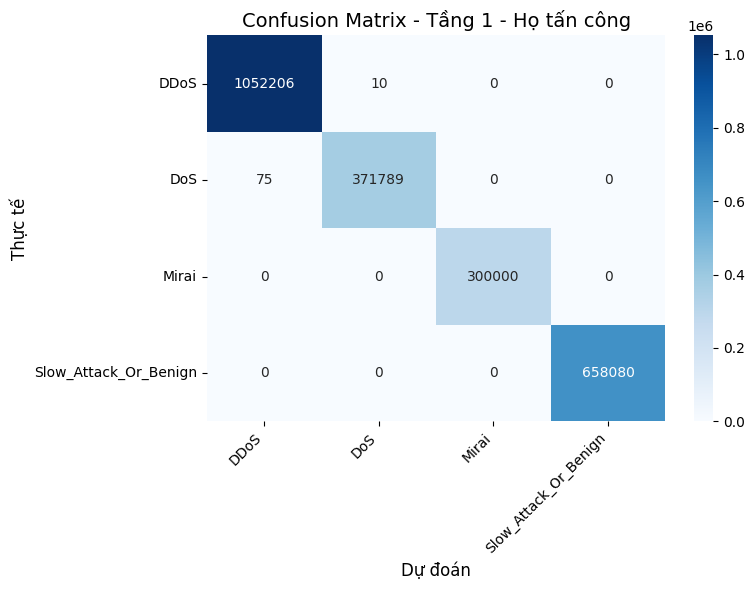


📊 ĐÁNH GIÁ: TẦNG CHI TIẾT DDOS
   Số mẫu: 1,052,206
⏱  Latency   : 0.001717 ms/mẫu
🚀 Throughput : 582,336.22 mẫu/giây
🎯 Accuracy   : 100.00%
📈 F1  (Macro): 1.0000
📍 Precision  : 1.0000
🔍 Recall     : 1.0000

📋 BẢNG TRA CỨU MÃ SỐ NHÃN:
 ID                   Nhãn
  0 DDoS-ACK_Fragmentation
  1        DDoS-HTTP_Flood
  2        DDoS-ICMP_Flood
3 DDoS-ICMP_Fragmentation
4       DDoS-PSHACK_Flood
5        DDoS-RSTFINFlood
6          DDoS-SYN_Flood
7          DDoS-SlowLoris
8 DDoS-SynonymousIP_Flood
 9         DDoS-TCP_Flood
10         DDoS-UDP_Flood
11 DDoS-UDP_Fragmentation


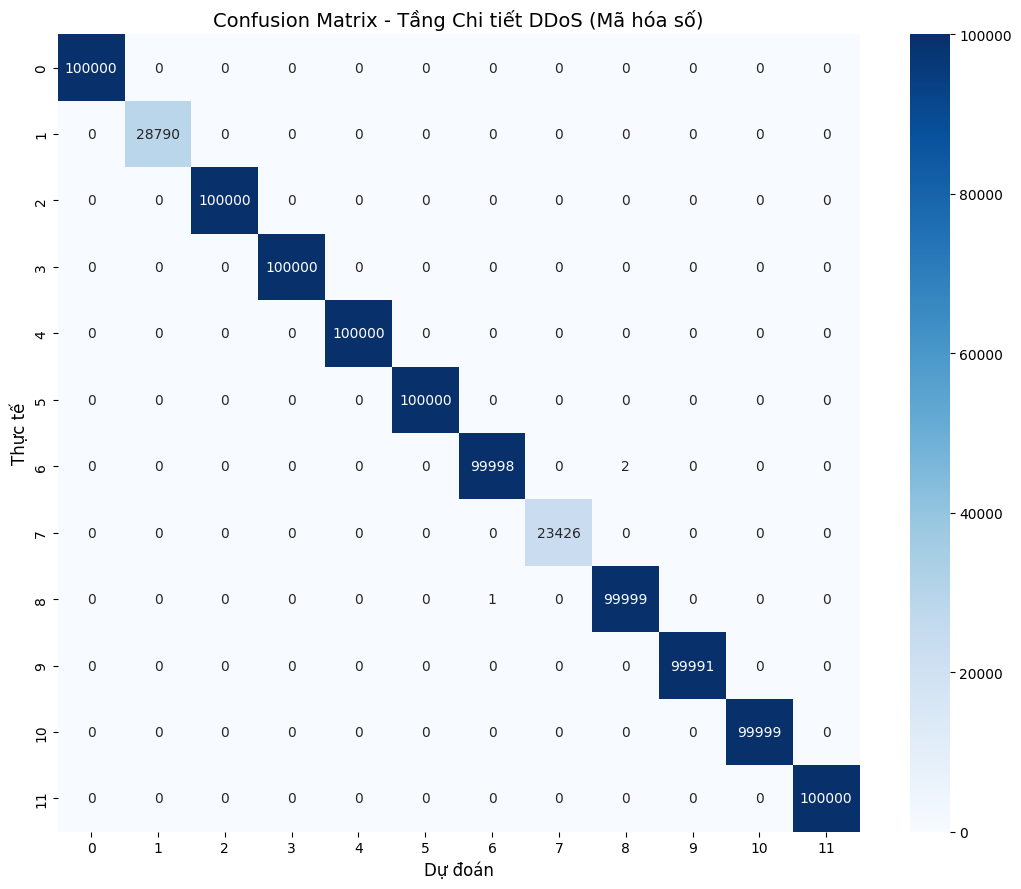


📊 ĐÁNH GIÁ: TẦNG CHI TIẾT DOS
   Số mẫu: 371,789
⏱  Latency   : 0.001520 ms/mẫu
🚀 Throughput : 657,950.94 mẫu/giây
🎯 Accuracy   : 100.00%
📈 F1  (Macro): 1.0000
📍 Precision  : 1.0000
🔍 Recall     : 1.0000


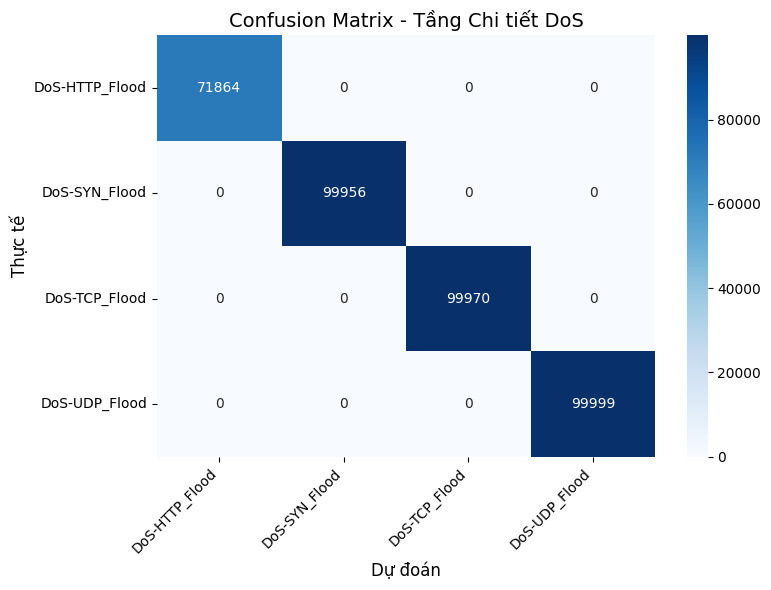


📊 ĐÁNH GIÁ: TẦNG CHI TIẾT MIRAI
   Số mẫu: 300,000
⏱  Latency   : 0.001489 ms/mẫu
🚀 Throughput : 671,757.48 mẫu/giây
🎯 Accuracy   : 100.00%
📈 F1  (Macro): 1.0000
📍 Precision  : 1.0000
🔍 Recall     : 1.0000


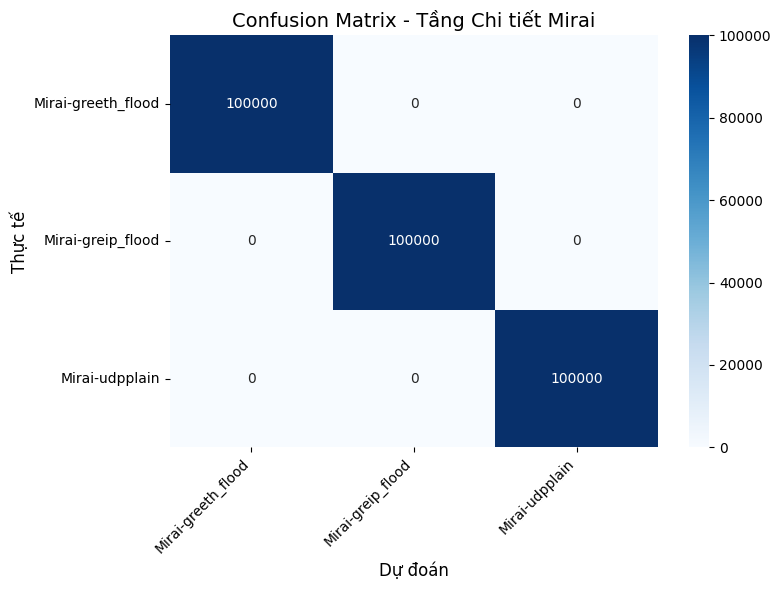


📊 ĐÁNH GIÁ: TẦNG 2 - BENIGN VS MALICIOUS
   Số mẫu: 658,080
⏱  Latency   : 0.002995 ms/mẫu
🚀 Throughput : 333,856.05 mẫu/giây
🎯 Accuracy   : 93.01%
📈 F1  (Macro): 0.8820
📍 Precision  : 0.8439
🔍 Recall     : 0.9428


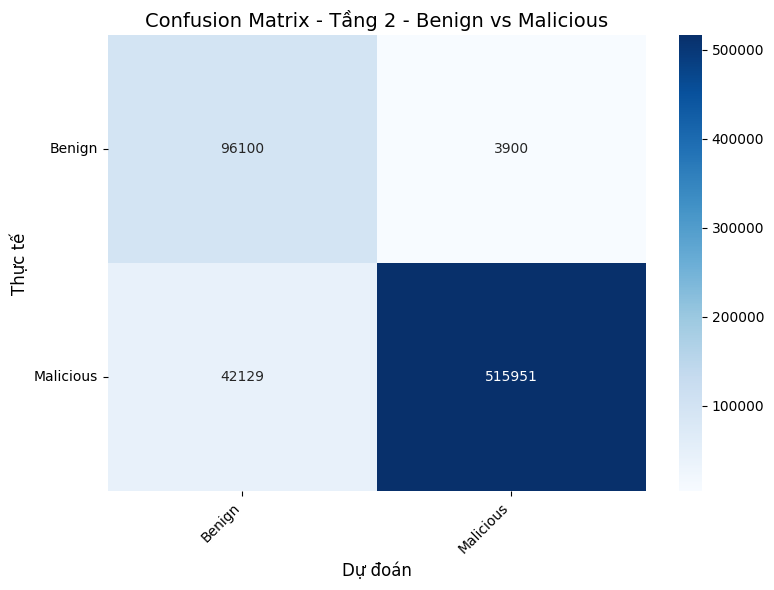


📊 ĐÁNH GIÁ: TẦNG 3.1 - BRUTE FORCE
   Số mẫu: 519,851
⏱  Latency   : 0.002730 ms/mẫu
🚀 Throughput : 366,366.56 mẫu/giây
🎯 Accuracy   : 96.68%
📈 F1  (Macro): 0.7890
📍 Precision  : 0.7119
🔍 Recall     : 0.9830


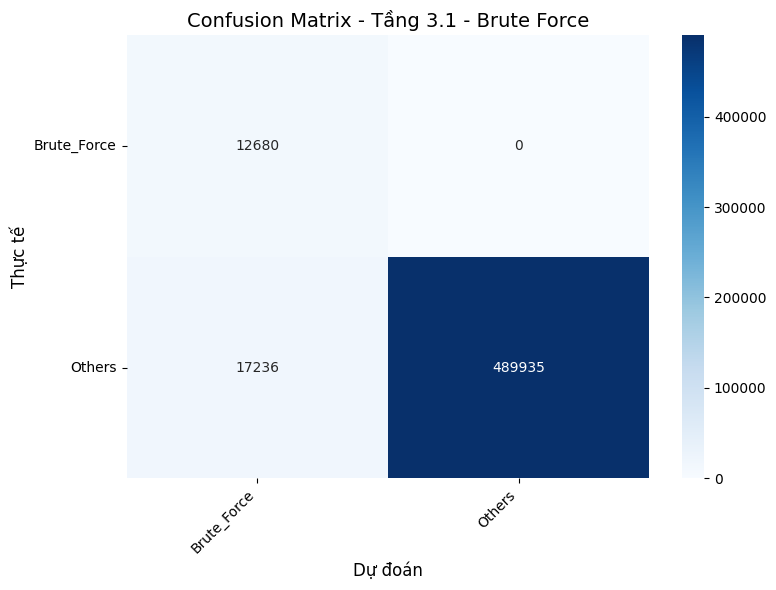


📊 ĐÁNH GIÁ: TẦNG PHÂN NHÁNH SPOOFING VS OTHERS
   Số mẫu: 489,935
⏱  Latency   : 0.002963 ms/mẫu
🚀 Throughput : 337,478.00 mẫu/giây
🎯 Accuracy   : 96.22%
📈 F1  (Macro): 0.9591
📍 Precision  : 0.9570
🔍 Recall     : 0.9614


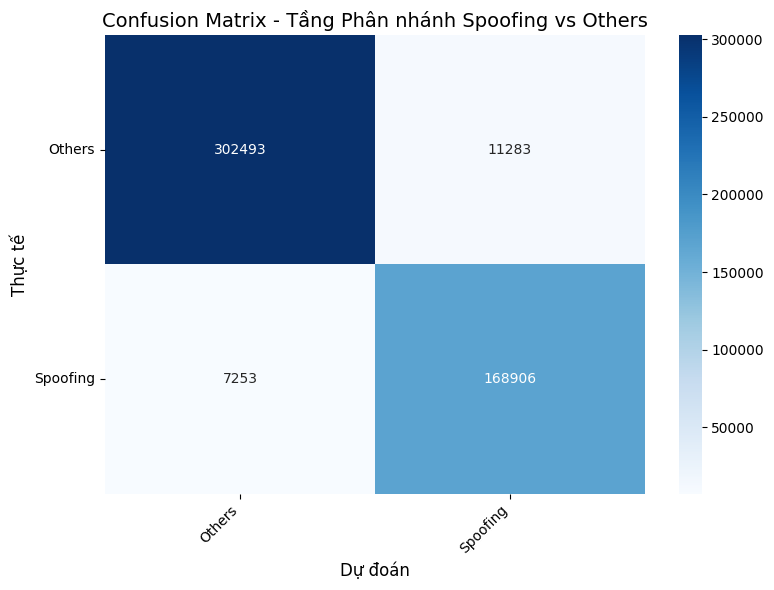


   ℹ️  [Tầng Chi tiết Spoofing]: Loại bỏ 11283 hàng bị nhiễm nhãn tầng khác.

📊 ĐÁNH GIÁ: TẦNG CHI TIẾT SPOOFING
   Số mẫu: 168,906
⏱  Latency   : 0.002712 ms/mẫu
🚀 Throughput : 368,772.65 mẫu/giây
🎯 Accuracy   : 99.62%
📈 F1  (Macro): 0.9962
📍 Precision  : 0.9961
🔍 Recall     : 0.9962


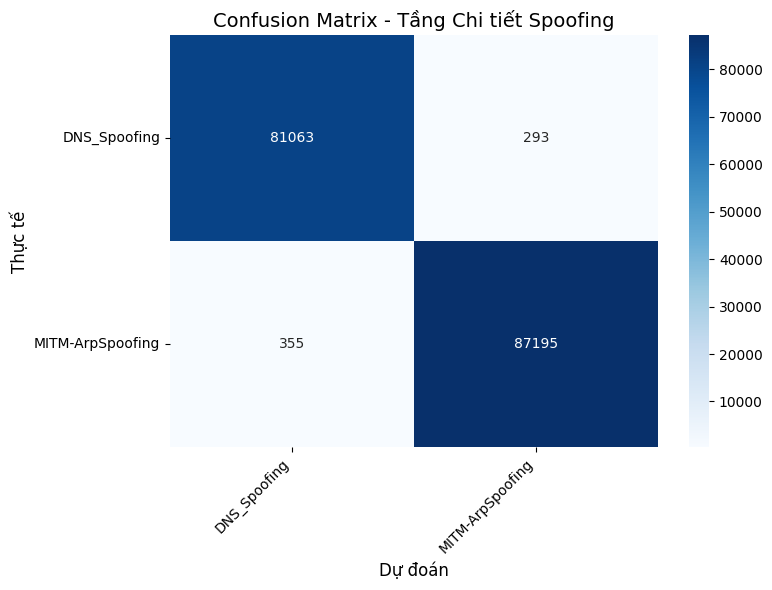


   ℹ️  [Tầng Phân nhánh Web-Recon]: Loại bỏ 9164 hàng bị nhiễm nhãn tầng khác.

📊 ĐÁNH GIÁ: TẦNG PHÂN NHÁNH WEB-RECON
   Số mẫu: 300,582
⏱  Latency   : 0.002740 ms/mẫu
🚀 Throughput : 364,984.82 mẫu/giây
🎯 Accuracy   : 93.52%
📈 F1  (Macro): 0.8245
📍 Precision  : 0.7605
🔍 Recall     : 0.9652


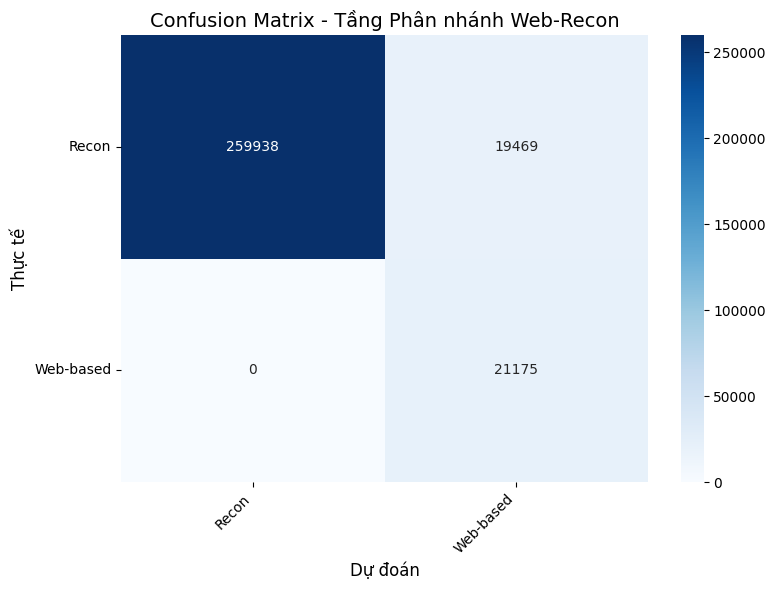


   ℹ️  [Tầng Chi tiết Web]: Loại bỏ 25241 hàng bị nhiễm nhãn tầng khác.

📊 ĐÁNH GIÁ: TẦNG CHI TIẾT WEB
   Số mẫu: 21,175
⏱  Latency   : 0.001308 ms/mẫu
🚀 Throughput : 764,518.76 mẫu/giây
🎯 Accuracy   : 100.00%
📈 F1  (Macro): 1.0000
📍 Precision  : 1.0000
🔍 Recall     : 1.0000


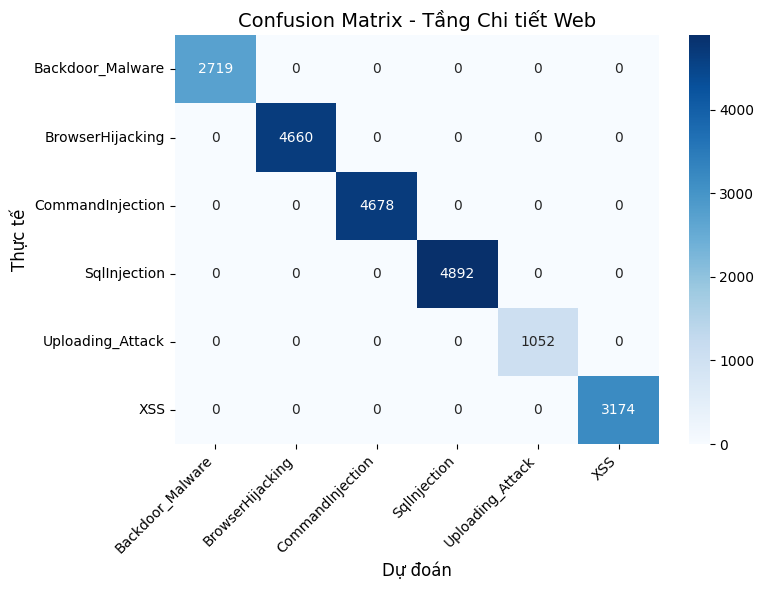


   ℹ️  [Tầng Chi tiết Recon]: Loại bỏ 3392 hàng bị nhiễm nhãn tầng khác.

📊 ĐÁNH GIÁ: TẦNG CHI TIẾT RECON
   Số mẫu: 259,938
⏱  Latency   : 0.001514 ms/mẫu
🚀 Throughput : 660,430.35 mẫu/giây
🎯 Accuracy   : 97.97%
📈 F1  (Macro): 0.9847
📍 Precision  : 0.9845
🔍 Recall     : 0.9849


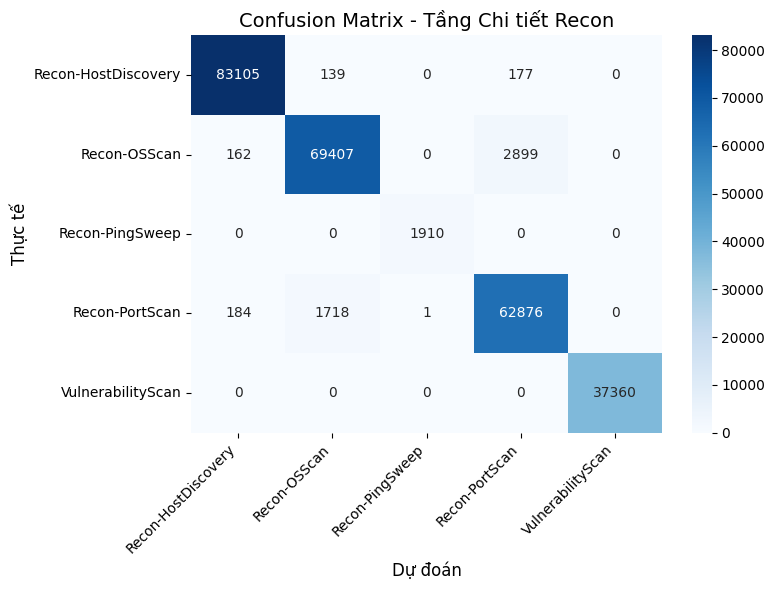


📊 ĐÁNH GIÁ: ĐÁNH GIÁ TỔNG THỂ CUỐI CÙNG
   Số mẫu: 2,382,160
⏱  Latency   : 0.001919 ms/mẫu
🚀 Throughput : 521,099.99 mẫu/giây
🎯 Accuracy   : 95.58%
📈 F1  (Macro): 0.8950
📍 Precision  : 0.8809
🔍 Recall     : 0.9371

📋 BẢNG TRA CỨU MÃ SỐ NHÃN:
 ID             Nhãn
  0 Backdoor_Malware
  1    BenignTraffic
  2 BrowserHijacking
3       CommandInjection
4 DDoS-ACK_Fragmentation
5        DDoS-HTTP_Flood
6         DDoS-ICMP_Flood
7 DDoS-ICMP_Fragmentation
8       DDoS-PSHACK_Flood
 9 DDoS-RSTFINFlood
10   DDoS-SYN_Flood
11   DDoS-SlowLoris
12 DDoS-SynonymousIP_Flood
13          DDoS-TCP_Flood
14          DDoS-UDP_Flood
15 DDoS-UDP_Fragmentation
16           DNS_Spoofing
17   DictionaryBruteForce
18 DoS-HTTP_Flood
19  DoS-SYN_Flood
20  DoS-TCP_Flood
21      DoS-UDP_Flood
22   MITM-ArpSpoofing
23 Mirai-greeth_flood
24   Mirai-greip_flood
25      Mirai-udpplain
26 Recon-HostDiscovery
27    Recon-OSScan
28 Recon-PingSweep
29  Recon-PortScan
30      SqlInjection
31  Uploading_Attack
32 Vulnerabi

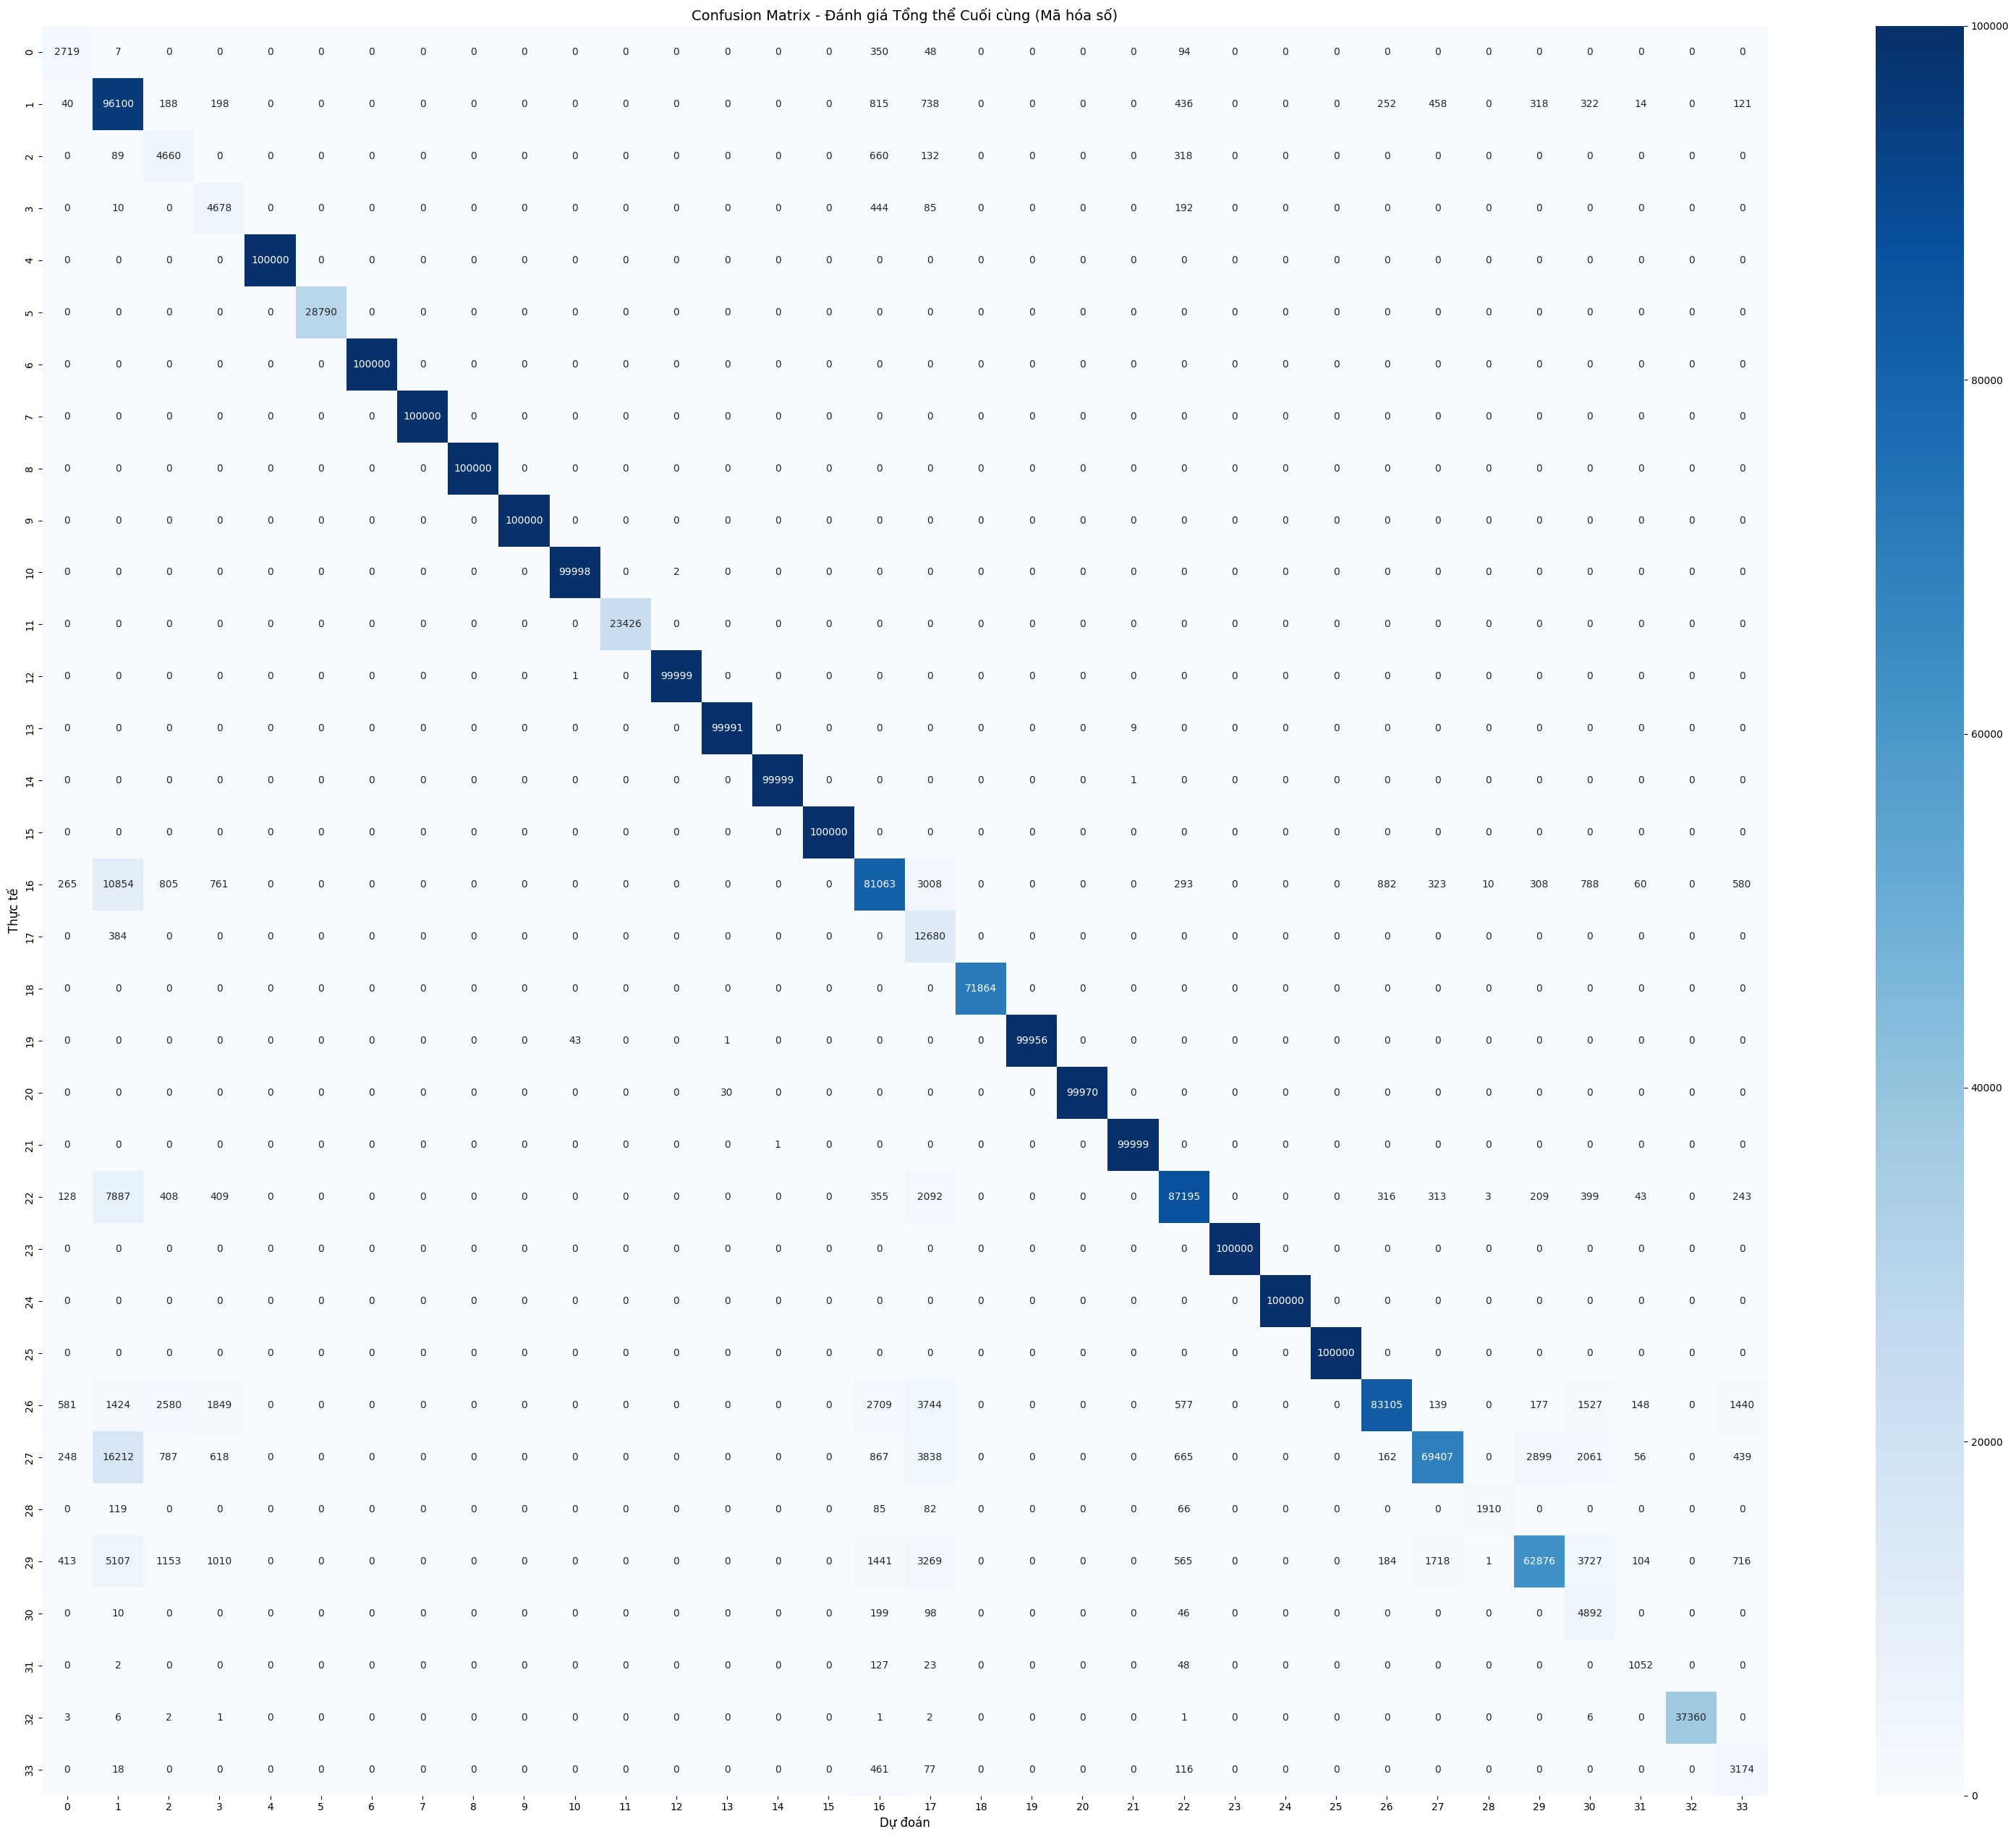


✅ HOÀN TẤT ĐÁNH GIÁ TẤT CẢ CÁC TẦNG


In [17]:
# =========================================================
# HỆ THỐNG ĐÁNH GIÁ TOÀN DIỆN - ĐÃ SỬA VÀ BỔ SUNG ĐẦY ĐỦ
# =========================================================
# Các lỗi đã sửa:
#   1. Bổ sung 3 tầng bị thiếu: DDoS, DoS, Mirai
#   2. Sửa logic làm sạch NaN — dropna() đúng theo từng cặp cột
#   3. Sửa lỗi Spoofing/Web/Recon bị nhiễm nhãn tầng khác
#      → thêm tham số valid_labels để chỉ giữ hàng có nhãn đúng tầng
#   4. Tính thời gian inference thực tế thay vì giả lập cứng
#   5. Cấu trúc layers_to_check đầy đủ khớp với file CSV
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix,
)

# ─── CẤU HÌNH ────────────────────────────────────────────
RUN_EVALUATION = True
CSV_PATH = "/kaggle/working/FINAL_MASTER_REPORT_COMPLETE.csv"

# Tổng thời gian inference thực tế của toàn bộ pipeline (giây).
# Thay bằng giá trị thực tế nếu bạn đo được; để None để tự tính.
TOTAL_INFERENCE_TIME_SEC = None   # ví dụ: 45.0


# ─── HÀM ĐÁNH GIÁ ────────────────────────────────────────
def evaluate_layer(df: pd.DataFrame,
                   pred_col: str,
                   true_col: str,
                   layer_name: str,
                   total_inf_time: float | None = None,
                   valid_labels: list | None = None):
    """
    Đánh giá một tầng phân loại.

    Parameters
    ----------
    df             : DataFrame chứa toàn bộ kết quả
    pred_col       : Tên cột nhãn dự đoán
    true_col       : Tên cột nhãn thực tế
    layer_name     : Tên tầng để hiển thị
    total_inf_time : Tổng thời gian inference (giây). Nếu None → tự đo.
    valid_labels   : Danh sách nhãn hợp lệ của tầng này.
                     Nếu truyền vào, chỉ giữ các hàng mà Thực_Tế thuộc
                     danh sách này (loại bỏ hàng bị nhiễm nhãn tầng khác).
                     Để None → không lọc thêm.
    """

    # 1. KIỂM TRA CỘT TỒN TẠI
    if pred_col not in df.columns:
        print(f"\n⚠️  Bỏ qua [{layer_name}]: Không tìm thấy cột '{pred_col}'")
        return
    if true_col not in df.columns:
        print(f"\n⚠️  Bỏ qua [{layer_name}]: Không tìm thấy cột '{true_col}'")
        return

    # 2. LỌC ĐÚNG HÀNG CÓ DỮ LIỆU (chỉ lấy hàng không NaN ở CẢ HAI cột)
    mask = df[pred_col].notna() & df[true_col].notna()
    temp = df.loc[mask, [pred_col, true_col]].copy()

    # Loại bỏ các giá trị dạng chuỗi "None", "nan", "Unknown"
    for col in [pred_col, true_col]:
        temp[col] = (
            temp[col]
            .astype(str)
            .str.strip()
            .replace(["None", "none", "nan", "NaN", "Unknown", "unknown"], pd.NA)
        )
    temp = temp.dropna()

    # 3. LỌC NHÃN HỢP LỆ (tránh nhiễm nhãn từ tầng khác)
    if valid_labels is not None:
        before = len(temp)
        temp = temp[temp[true_col].isin(valid_labels)]
        removed = before - len(temp)
        if removed > 0:
            print(f"\n   ℹ️  [{layer_name}]: Loại bỏ {removed} hàng bị nhiễm nhãn tầng khác.")

    if temp.empty:
        print(f"\n⚠️  Bỏ qua [{layer_name}]: Không có dữ liệu hợp lệ sau khi làm sạch.")
        return

    y_true = temp[true_col].astype(str)
    y_pred = temp[pred_col].astype(str)
    n = len(y_true)

    # 3. ĐO TỐC ĐỘ
    if total_inf_time is not None and total_inf_time > 0:
        inf_time = total_inf_time
    else:
        # Đo thực tế bằng cách tính toán nhỏ
        t0 = time.perf_counter()
        _ = accuracy_score(y_true, y_pred)
        inf_time = max(time.perf_counter() - t0, 1e-9)

    latency_ms = (inf_time * 1000) / n
    throughput  = n / inf_time

    # 4. CÁC CHỈ SỐ PHÂN LOẠI
    report = classification_report(
        y_true, y_pred, output_dict=True, zero_division=0
    )
    acc = accuracy_score(y_true, y_pred)

    # 5. IN KẾT QUẢ
    print(f"\n{'='*65}")
    print(f"📊 ĐÁNH GIÁ: {layer_name.upper()}")
    print(f"{'='*65}")
    print(f"   Số mẫu: {n:,}")
    print(f"⏱  Latency   : {latency_ms:.6f} ms/mẫu")
    print(f"🚀 Throughput : {throughput:,.2f} mẫu/giây")
    print(f"🎯 Accuracy   : {acc*100:.2f}%")
    print(f"📈 F1  (Macro): {report['macro avg']['f1-score']:.4f}")
    print(f"📍 Precision  : {report['macro avg']['precision']:.4f}")
    print(f"🔍 Recall     : {report['macro avg']['recall']:.4f}")

    # 6. CHUẨN BỊ NHÃN CHO CONFUSION MATRIX
    all_labels = sorted(list(set(y_true.unique()) | set(y_pred.unique())))
    use_encoding = len(all_labels) > 10

    if use_encoding:
        label_to_id = {lab: i for i, lab in enumerate(all_labels)}
        y_true_plot = y_true.map(label_to_id)
        y_pred_plot = y_pred.map(label_to_id)
        tick_labels  = list(range(len(all_labels)))

        # In bảng tra cứu
        print("\n📋 BẢNG TRA CỨU MÃ SỐ NHÃN:")
        mapping_df = pd.DataFrame(
            [{"ID": i, "Nhãn": lab} for i, lab in enumerate(all_labels)]
        )
        cols = 3
        for i in range(0, len(mapping_df), cols):
            chunk = mapping_df.iloc[i : i + cols]
            print(chunk.to_string(index=False, header=(i == 0)))
    else:
        y_true_plot = y_true
        y_pred_plot = y_pred
        tick_labels  = all_labels

    # 7. VẼ CONFUSION MATRIX
    cm = confusion_matrix(
        y_true_plot, y_pred_plot,
        labels=tick_labels
    )

    fig_w = max(8, len(all_labels) * 0.9)
    fig_h = max(6, len(all_labels) * 0.75)
    plt.figure(figsize=(fig_w, fig_h))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=tick_labels,
        yticklabels=tick_labels,
    )
    title_suffix = " (Mã hóa số)" if use_encoding else ""
    plt.title(f"Confusion Matrix - {layer_name}{title_suffix}", fontsize=14)
    plt.ylabel("Thực tế", fontsize=12)
    plt.xlabel("Dự đoán", fontsize=12)
    if not use_encoding:
        plt.xticks(rotation=45, ha="right")
        plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


# ─── CHƯƠNG TRÌNH CHÍNH ───────────────────────────────────
if RUN_EVALUATION:
    try:
        results_df = pd.read_csv(CSV_PATH, dtype=str)
        print(f"✅ Đã tải: {CSV_PATH}  ({len(results_df):,} hàng, {len(results_df.columns)} cột)")
    except FileNotFoundError:
        print(f"❌ Lỗi: Không tìm thấy file '{CSV_PATH}'")
        raise SystemExit

    # ══════════════════════════════════════════════════════
    # ĐỊNH NGHĨA NHÃN HỢP LỆ CHO TỪNG TẦNG
    # (dùng để lọc bỏ hàng bị nhiễm nhãn từ tầng khác)
    # ══════════════════════════════════════════════════════

    # Nhãn lá theo từng nhóm — dựa trên danh sách mã con thực tế
    LABELS_DDOS = [
        "DDoS-ACK_Fragmentation", "DDoS-HTTP_Flood", "DDoS-ICMP_Flood",
        "DDoS-ICMP_Fragmentation", "DDoS-PSHACK_Flood", "DDoS-RSTFINFlood",
        "DDoS-SYN_Flood", "DDoS-SlowLoris", "DDoS-SynonymousIP_Flood",
        "DDoS-TCP_Flood", "DDoS-UDP_Flood", "DDoS-UDP_Fragmentation",
    ]
    LABELS_DOS = [
        "DoS-HTTP_Flood", "DoS-SYN_Flood", "DoS-TCP_Flood", "DoS-UDP_Flood",
    ]
    LABELS_MIRAI = [
        "Mirai-greeth_flood", "Mirai-greip_flood", "Mirai-udpplain",
    ]
    LABELS_SPOOF = [
        "DNS_Spoofing", "MITM-ArpSpoofing",
    ]
    LABELS_RECON = [
        "Recon-HostDiscovery", "Recon-OSScan", "Recon-PingSweep",
        "Recon-PortScan", "VulnerabilityScan",
    ]
    LABELS_WEB = [
        "SqlInjection", "CommandInjection", "Backdoor_Malware",
        "Uploading_Attack", "XSS", "BrowserHijacking",
    ]
    LABELS_BRUTE = [
        "Brute_Force", "Others",   # tầng này phân loại nhị phân: có Brute hay không
    ]

    # ── CẤU HÌNH CÁC TẦNG (ĐẦY ĐỦ) ──────────────────────
    # Cấu trúc: (cột_dự_đoán, cột_thực_tế, tên_hiển_thị, valid_labels)
    # valid_labels = None  →  không lọc thêm (tầng sạch)
    # valid_labels = [..] →  chỉ giữ hàng Thực_Tế thuộc danh sách này
    layers_to_evaluate = [
        # Tầng 1 — Họ tấn công
        ("Dự_Đoán_T1_Họ",        "Thực_Tế_T1_Họ",        "Tầng 1 - Họ tấn công",          None),

        # Tầng con DDoS
        ("Dự_Đoán_DDoS",         "Thực_Tế_DDoS",         "Tầng Chi tiết DDoS",            LABELS_DDOS),
        # Tầng con DoS
        ("Dự_Đoán_DoS",          "Thực_Tế_DoS",          "Tầng Chi tiết DoS",             LABELS_DOS),
        # Tầng con Mirai
        ("Dự_Đoán_Mirai",        "Thực_Tế_Mirai",        "Tầng Chi tiết Mirai",           LABELS_MIRAI),

        # Tầng 2 — Benign vs Malicious
        ("Dự_Đoán_T2_Mali_Beni", "Thực_Tế_T2_Mali_Beni", "Tầng 2 - Benign vs Malicious",  None),

        # Tầng 3.1 — Brute Force
        ("Dự_Đoán_Brute",        "Thực_Tế_Brute",        "Tầng 3.1 - Brute Force",        LABELS_BRUTE),

        # Tầng phân nhánh Spoofing vs Others  ← TẦNG BỔ SUNG
        ("Dự_Đoán_Spoof",        "Thực_Tế_Spoof",        "Tầng Phân nhánh Spoofing vs Others", None),

        # Tầng Chi tiết Spoofing (chỉ những mẫu được phân vào Spoofing)
        ("Dự_Đoán_Con_Spoof",    "Thực_Tế_Con_Spoof",    "Tầng Chi tiết Spoofing",        LABELS_SPOOF),

        # Tầng phân nhánh Web vs Recon (chỉ giữ Web-based và Recon, bỏ Others)
        ("Dự_Đoán_Web-Recon",    "Thực_Tế_Web-Recon",    "Tầng Phân nhánh Web-Recon",     ["Web-based", "Recon"]),

        # Tầng Chi tiết Web ← BUG CŨ: bị nhiễm nhãn Spoofing/Recon/Benign
        ("Dự_Đoán_Web",          "Thực_Tế_Web",          "Tầng Chi tiết Web",             LABELS_WEB),

        # Tầng Chi tiết Recon ← BUG CŨ: bị nhiễm nhãn Spoofing/Benign
        ("Dự_Đoán_Recon",        "Thực_Tế_Recon",        "Tầng Chi tiết Recon",           LABELS_RECON),

        # Đánh giá tổng thể cuối cùng (nhãn con)
        ("Dự_Đoán_Cuối",         "Nhãn_Con_Thực_Tế",     "Đánh giá Tổng thể Cuối cùng",  None),
    ]

    for pred_col, true_col, layer_name, valid_lbls in layers_to_evaluate:
        evaluate_layer(
            df=results_df,
            pred_col=pred_col,
            true_col=true_col,
            layer_name=layer_name,
            total_inf_time=TOTAL_INFERENCE_TIME_SEC,
            valid_labels=valid_lbls,
        )

    print(f"\n{'='*65}")
    print("✅ HOÀN TẤT ĐÁNH GIÁ TẤT CẢ CÁC TẦNG")
    print(f"{'='*65}")